# [GSE242033](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE242033)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2025-07-14
> - Modified: 2025-07-14

# 1. Experimental Design

> SETD3 regulates endoderm differentiation of mouse embryonic stem cells through its effect on the canonical Wnt signaling pathway activity.
> - Alganatay C, Balbasi E, Tuncbag N, Sezginmert D, Terzi Cizmecioglu N. SETD3 regulates endoderm differentiation of mouse embryonic stem cells through canonical Wnt signaling pathway. The FASEB Journal. 2024;38:e23463. doi:10.1096/fj.202301883R.
> - polyA RNA-seq
> - Illumina HiSeq 2000, PE150
> - mm10

| Sample | Organism | Cell | Source | Strain | Genotype | Treatment | Time | Replicate |
| - | - | - | - | - | - | - | - | - |
| WT | Mus musculus | mESC | Embryionic stem cell | CJ9 | Wild-type | endoderm differentiation | D0, D2, D3, D4 | rep1~3 |
| KO | Mus musculus | mESC | Embryionic stem cell | CJ9 | Setd3 knock-out | endoderm differentiation | D0, D2, D3, D4 | rep1~3 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Setd3_GSE242033/02_output"

### a). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _)

dim(raw_counts)

[1] 55335    32

In [4]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("mESC"))) |>
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Time", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        sample = sub("^[^_]+_[^_]+_", "", sample),
        Group = factor(Group, levels = c("WT", "KO")), 
        Time = factor(Time), 
        Replicate = factor(Replicate)) |> 
    arrange(Group, Time, Replicate) |>
    column_to_rownames("sample")

head(coldata)

,Cell,Gene,Group,Time,Replicate
,<chr>,<chr>,<fct>,<fct>,<fct>
WT_D0_rep1,mESC,Setd3,WT,D0,rep1
WT_D0_rep2,mESC,Setd3,WT,D0,rep2
WT_D0_rep3,mESC,Setd3,WT,D0,rep3
WT_D2_rep1,mESC,Setd3,WT,D2,rep1
WT_D2_rep2,mESC,Setd3,WT,D2,rep2
WT_D2_rep3,mESC,Setd3,WT,D2,rep3


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("mESC")) |>
    rename_with(~ sub("^[^_]+_[^_]+_", "", .x)) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Time + Group)

class: DESeqDataSet 
dim: 55335 24 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(24): WT_D0_rep1 WT_D0_rep2 ... KO_D4_rep2 KO_D4_rep3
colData names(5): Cell Gene Group Time Replicate

### b). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE)

In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Gene", "Group", "Time", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sampleName = sub("^[^_]+_[^_]+_", "", sampleName), 
        Group = factor(Group, levels = c("WT", "KO")), 
        Time = factor(Time),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Time, Replicate) |>
    select("sampleName", "fileName", "Cell", "Gene", "Group", "Time", "Replicate") |>
    as.data.frame()

In [10]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Time + Group,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 55335 24 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(24): WT_D0_rep1 WT_D0_rep2 ... KO_D4_rep2 KO_D4_rep3
colData names(5): Cell Gene Group Time Replicate

### c). Salmon

#### tximport

In [11]:
gtf <- rtracklayer::import(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

In [12]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE)
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

In [13]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Time", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_[^_]+_", "", sample), 
        Group = factor(Group, levels = c("WT", "KO")), 
        Time = factor(Time),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Time, Replicate) |>
    column_to_rownames("sample")

names(salmon_quants) <- sub("^[^_]+_[^_]+_", "", names(salmon_quants))
salmon_quants <- salmon_quants[rownames(coldata)]

In [14]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 


summarizing abundance

summarizing counts

summarizing length



In [15]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Time + Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 54281 24 
metadata(1): version
assays(2): counts avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(24): WT_D0_rep1 WT_D0_rep2 ... KO_D4_rep2 KO_D4_rep3
colData names(5): Cell Gene Group Time Replicate

#### tximeta

In [16]:
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE)

In [17]:
coldata <- tibble(
    names = salmon_dirs, 
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")) |> 
    separate(
        col = names, into = c("Cell", "Gene", "Group", "Time", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        names = sub("^[^_]+_[^_]+_", "", names), 
        Group = factor(Group, levels = c("WT", "KO")), 
        Time = factor(Time),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Time, Replicate) |>
    select("names", "files", "Cell", "Gene", "Group", "Time", "Replicate") |>
    as.data.frame()

In [18]:
# suppressPackageStartupMessages(library(tximeta))
tximeta::makeLinkedTxome(
    indexDir = "~/reference/Mus_musculus/mm10/index/salmon_index", 
    source = "GENCODE", organism = "Mus musculus", 
    release = "M23", genome = "GRCm38",
    fasta = "~/reference/Mus_musculus/mm10/gencode.vM23.transcripts.fa", 
    gtf = "~/reference/Mus_musculus/mm10/index/genome.gtf", 
    write = FALSE)

reading digest from indexDir: ~/reference/Mus_musculus/mm10/index/salmon_index

NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE

saving linkedTxome in bfc (first time)



In [19]:
# There is a network problem
se <- tximeta::tximeta(coldata, useHub = FALSE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 


found matching linkedTxome:
[ GENCODE - Mus musculus - release M23 ]

building TxDb with 'txdbmaker' package

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"
OK

generating transcript ranges

fetching genome info for GENCODE

loading existing TxDb created: 2026-06-23 08:49:46

Loading required package: GenomicFeatures

Loading required package: AnnotationDbi


Attaching package: 'AnnotationDbi'


The following object is masked from 'package:dpl

In [20]:
DESeqDataSet(gse, design = ~ Time + Group)

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 54281 24 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(2): gene_id tx_ids
colnames(24): WT_D0_rep1 WT_D0_rep2 ... KO_D4_rep2 KO_D4_rep3
colData names(6): names Cell ... Time Replicate

### d). kallisto

#### tximport

In [21]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE)
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

In [22]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Time", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_[^_]+_", "", sample), 
        Group = factor(Group, levels = c("WT", "KO")), 
        Time = factor(Time),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Time, Replicate) |>
    column_to_rownames("sample")

names(kallisto_quants) <- sub("^[^_]+_[^_]+_", "", names(kallisto_quants))
kallisto_quants <- kallisto_quants[rownames(coldata)]

In [23]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 


summarizing abundance

summarizing counts

summarizing length



In [24]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Time + Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 55335 24 
metadata(1): version
assays(2): counts avgTxLength
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(24): WT_D0_rep1 WT_D0_rep2 ... KO_D4_rep2 KO_D4_rep3
colData names(5): Cell Gene Group Time Replicate

## 2). Object Construction

In [25]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 55335 24 
metadata(0):
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(24): WT_D0_rep1 WT_D0_rep2 ... KO_D4_rep2 KO_D4_rep3
colData names(5): Cell Gene Group Time Replicate

In [26]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Time + Group)

dds

class: DESeqDataSet 
dim: 55335 24 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(24): WT_D0_rep1 WT_D0_rep2 ... KO_D4_rep2 KO_D4_rep3
colData names(5): Cell Gene Group Time Replicate

In [27]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [28]:
keep <- rowSums(assay(eSet) >= 10) >= 3
# keep <- rowSums(counts(dds) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 17446 
 Remove: 37889 
 Retention rate: 31.53 %


In [29]:
design <- model.matrix(~ Time + Group, data = dgel$samples)
keep <- filterByExpr(dgel, design = design)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 16573 
 Remove: 38762 
 Retention rate: 29.95 %


# 3. Normalization

In [30]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [31]:
dds <- estimateSizeFactors(dds)
norm_fpkm <- fpkm(dds, robust = TRUE)

In [32]:
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [33]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [34]:
rld <- rlog(dds, blind = FALSE)

In [35]:
suppressPackageStartupMessages(library(vsn))

In [36]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [37]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


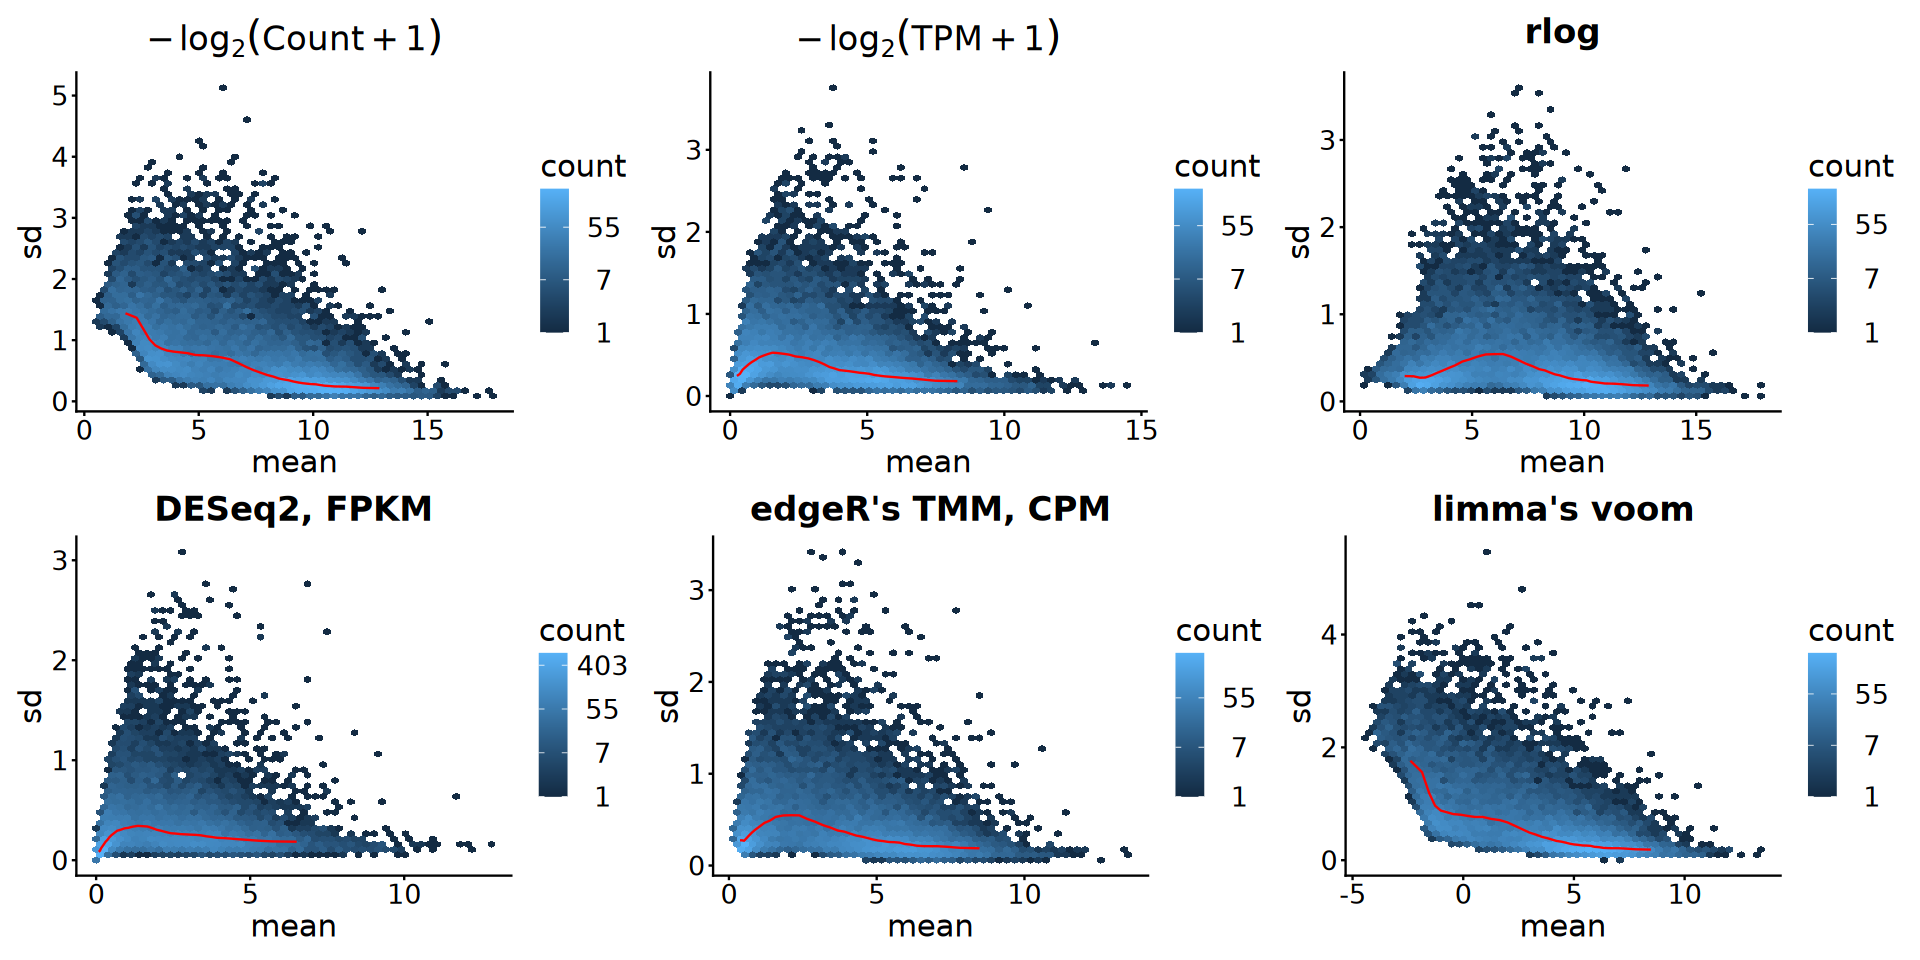

In [38]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [39]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [40]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Time, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

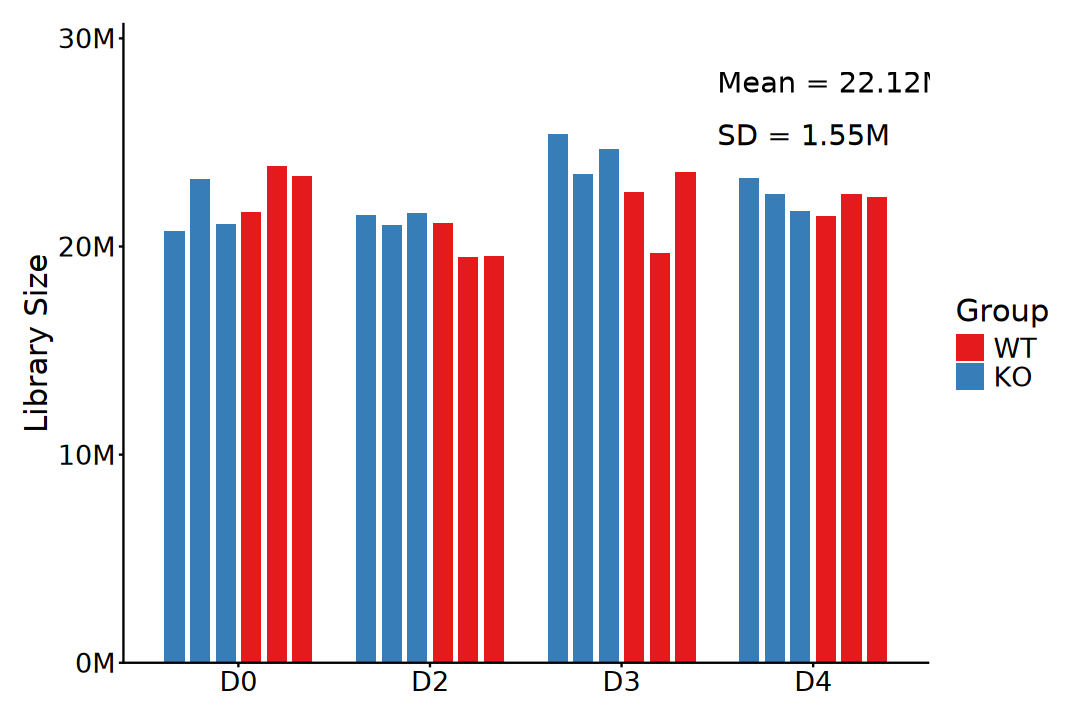

In [41]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Time, y = librarySize)) +
    geom_col(
        aes(fill = Group, group = Sample), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, show.legend = TRUE) +
    annotate(
        geom = "text", x = 3.5, y = max(plot_df$librarySize) * 1.1,
        label = paste0("Mean = ", round(mean(plot_df$librarySize) / 1e6, 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = 3.5, y = max(plot_df$librarySize) * 1.0,
        label = paste0("SD = ", round(sd(plot_df$librarySize) * 1e-6, 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set1") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). PCA

In [42]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 1000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [43]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [44]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Time, shape = Group), size = 5) +
    geom_smooth(
        aes(group = Group, color = Group), formula = "y ~ x", 
        method = "loess", se = FALSE, linewidth = 1) +
    scale_color_brewer(palette = "Dark2") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [45]:
pca_res <- plotPCA(
    rld, intgroup = c("Group", "Time", "Replicate"), 
    ntop = 1000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=1000 top features by variance



In [46]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Time, shape = Group), size = 5) +
    geom_smooth(
        aes(group = Group, color = Group), formula = "y ~ x", 
        method = "loess", se = FALSE, linewidth = 1) +
    scale_color_brewer(palette = "Dark2") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [47]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
set.seed(123)

gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [48]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Time, shape = Group), size = 5) +
    geom_smooth(
        aes(group = Group, color = Group), formula = "y ~ x", 
        method = "loess", se = FALSE, linewidth = 1) +
    scale_color_brewer(palette = "Dark2") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)),
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

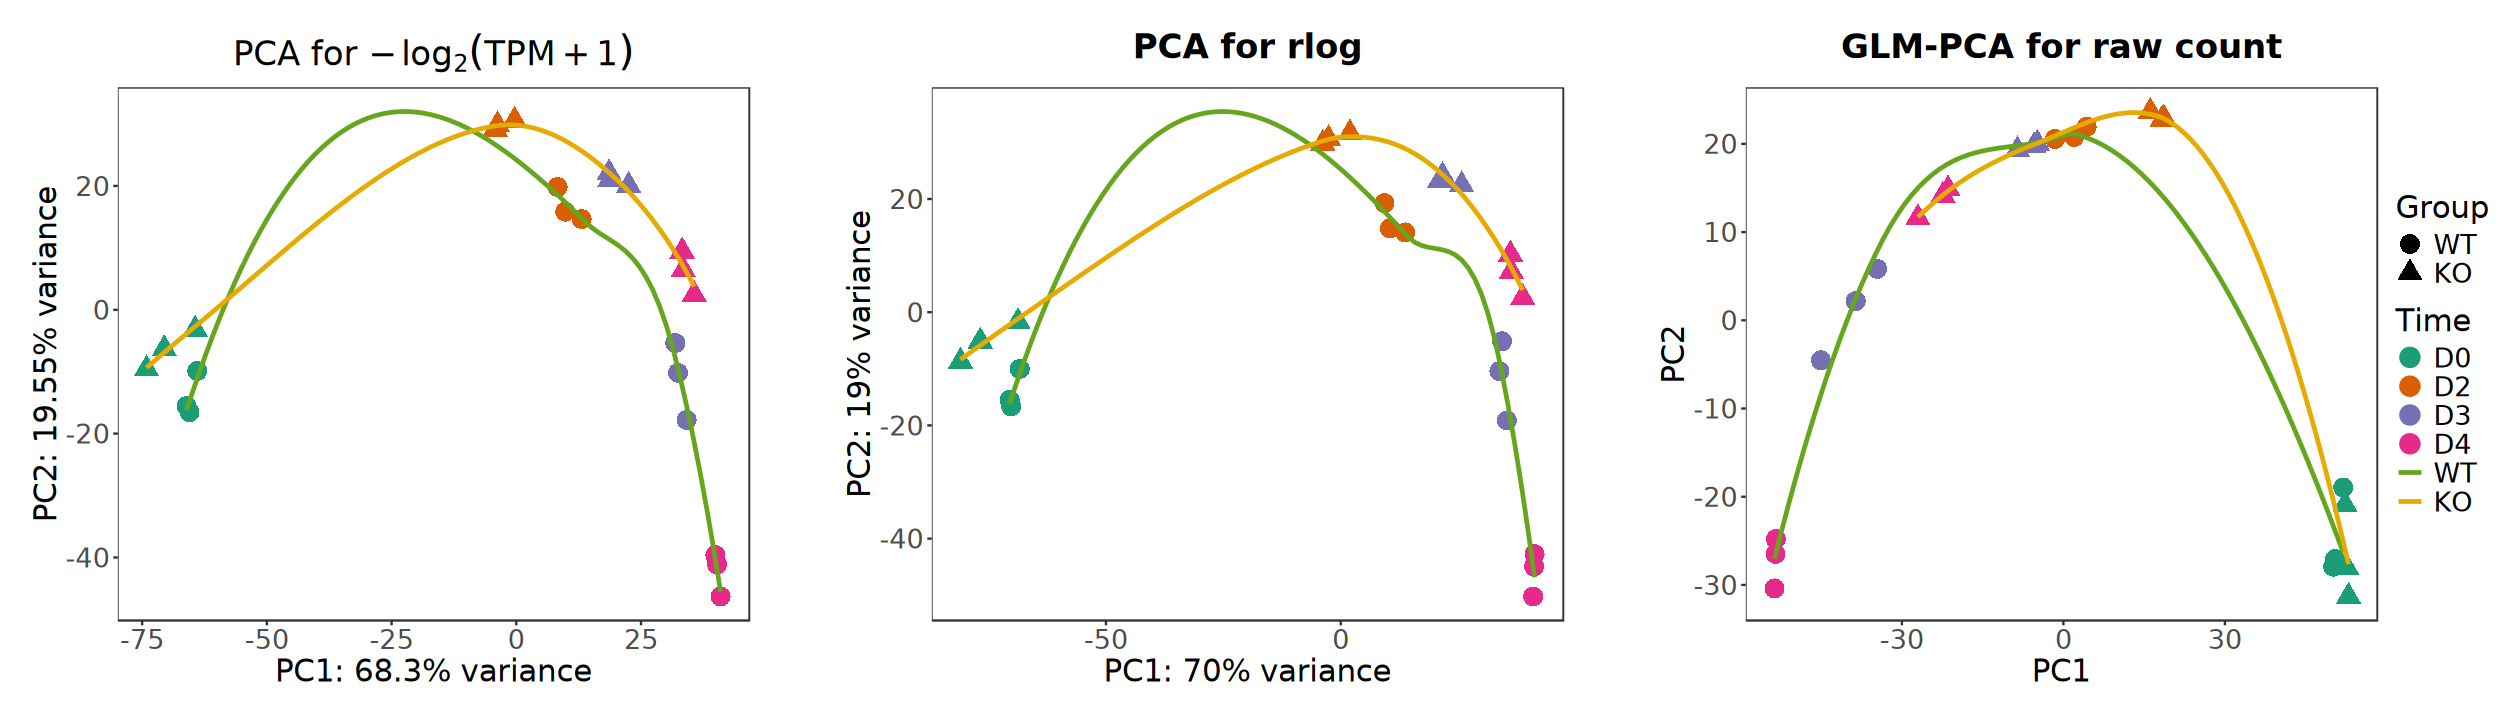

In [49]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [50]:
dist_mat <- norm_mat[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

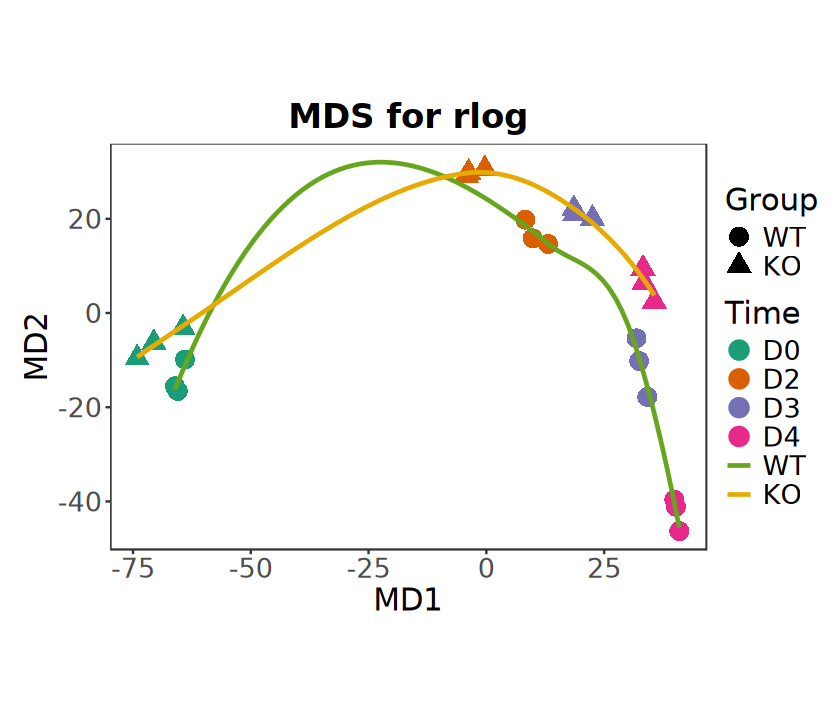

In [51]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Time, shape = Group), size = 5) +
    geom_smooth(
        aes(group = Group, color = Group), formula = "y ~ x", 
        method = "loess", se = FALSE, linewidth = 1) +
    scale_color_brewer(palette = "Dark2") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [52]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

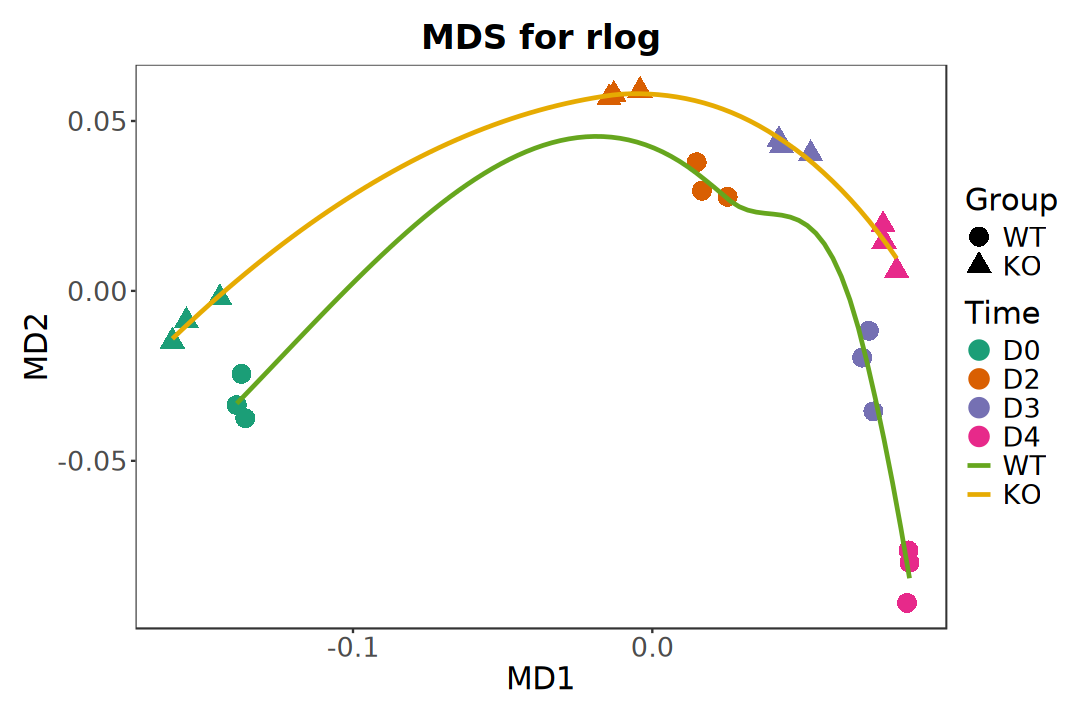

In [53]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Time, shape = Group), size = 5) +
    geom_smooth(
        aes(group = Group, color = Group), formula = "y ~ x", 
        method = "loess", se = FALSE, linewidth = 1) +
    scale_color_brewer(palette = "Dark2") +
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Correlation

In [54]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Time, Group)

In [55]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
time_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Time)),
    levels(eSet$Time))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Group = group_colors,
    Time = time_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [56]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

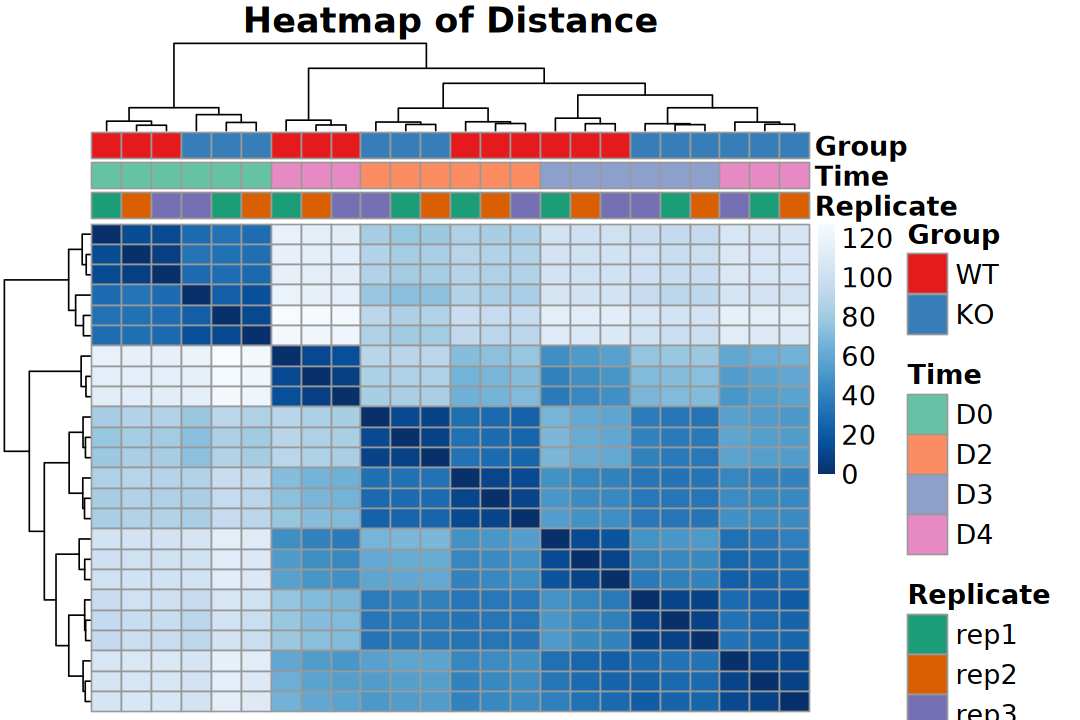

In [57]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [58]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

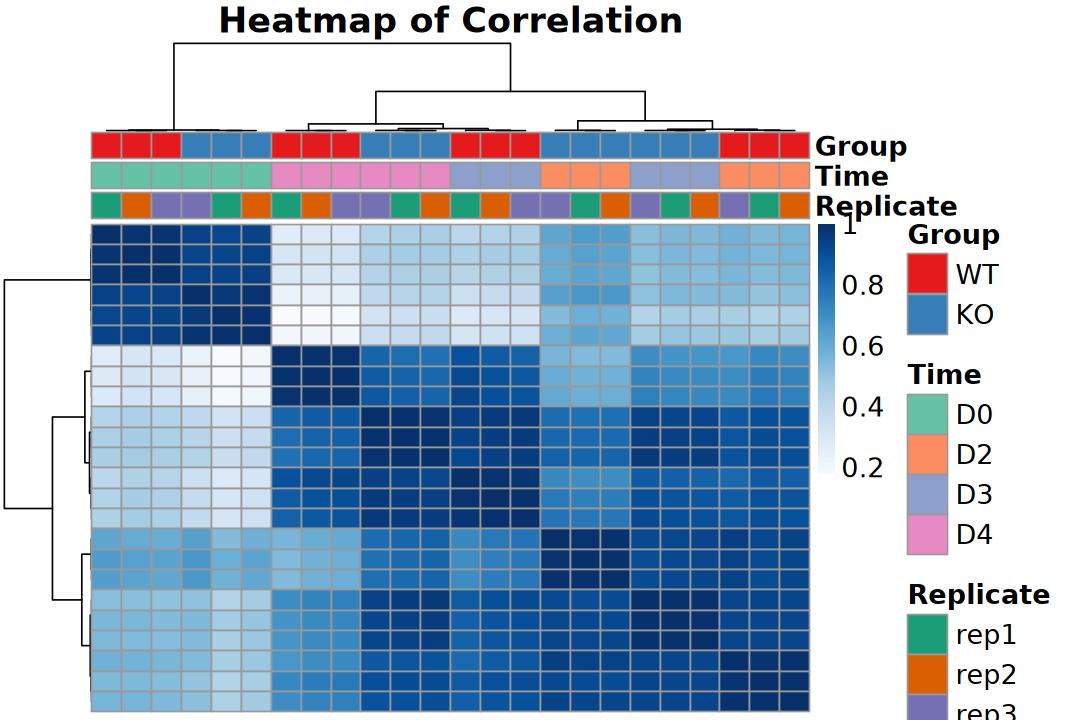

In [59]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

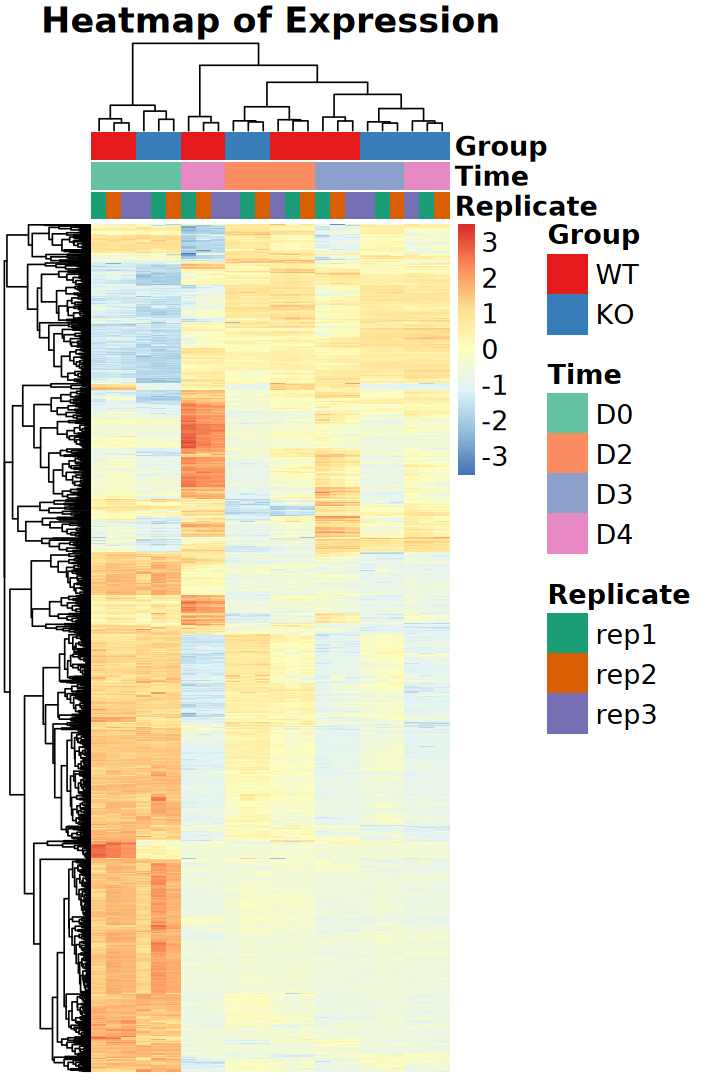

In [60]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [61]:
p1 <- pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE, 
    silent = TRUE)

In [62]:
p2 <- pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE, 
    cluster_cols = FALSE, silent = TRUE)

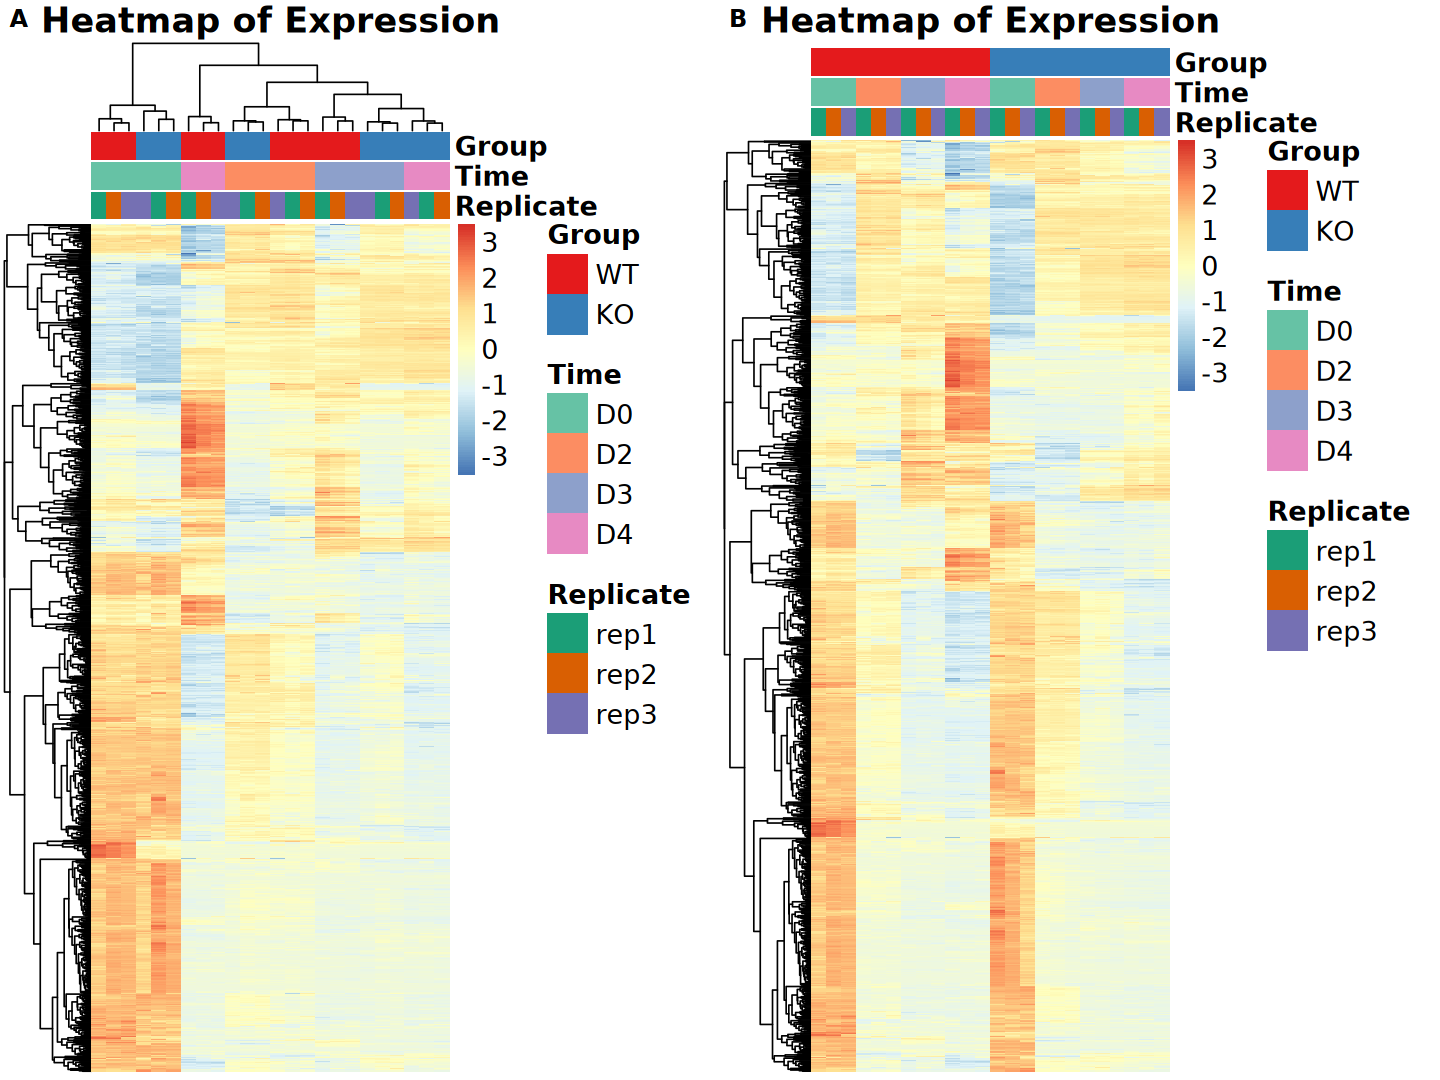

In [63]:
options(repr.plot.width = 12, repr.plot.height = 9)
cowplot::plot_grid(p1[[4]], p2[[4]], labels = c("A", "B"), ncol = 2)

# 5. DEGs: Pairwise

In [64]:
logfc_cutoff <- log2(2)
p_cutoff <- 0.05

## a). DESeq2

> median of ratios for normalization

In [65]:
# design(dds) <- ~ Group + Time + Group:Time
design(dds) <- ~ Group * Time
design(dds)

~Group * Time

In [66]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [67]:
resultsNames(dds)

[1] "Intercept"      "Group_KO_vs_WT" "Time_D2_vs_D0"  "Time_D3_vs_D0" 
[5] "Time_D4_vs_D0"  "GroupKO.TimeD2" "GroupKO.TimeD3" "GroupKO.TimeD4"

In [68]:
get_result_DESeq2 <- function(dds, group, timepoint) {
    rn <- resultsNames(dds)
    main_term <- rn[grep(paste0("^", group, ".*_vs_.*"), rn)]
    inter_term <- rn[grepl(timepoint, rn) & grepl(group, rn)]

    results(dds, contrast = list(main_term, inter_term)) |>
        as.data.frame() |> 
        rownames_to_column("gene_id") |>
        dplyr::rename(logFC = log2FoldChange) |>
        mutate(
            method = "DESeq2",
            contrast = timepoint,
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS"))) |>
        left_join(
            rowData(dds) |> as.data.frame() |> 
                dplyr::select(symbol, type, basepairs) |>
                rownames_to_column("gene_id"), 
            by = "gene_id")
}

In [69]:
contrast_labels <- levels(dds$Time)

deseq2_result_list <- map(
    contrast_labels, ~ get_result_DESeq2(
        dds = dds, group = "Group", timepoint = .x)) |> 
    set_names(contrast_labels)

In [70]:
deseq2_result_df <- bind_rows(deseq2_result_list) |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deseq2_result_df$contrast, deseq2_result_df$result)

    
        Up  Down    NS
  D0    94   489 16863
  D2   209   555 16682
  D3   372   912 16162
  D4  1038  1315 15093

## b). edgeR

> Trimmed Mean of M-values (TMM)
> 
> Quasi-likelihood pipeline

In [71]:
# design <- model.matrix(~ Group + Time + Group:Time, data = dgel$samples)
design <- model.matrix(~ Group * Time, data = dgel$samples)
colnames(design)

[1] "(Intercept)"    "GroupKO"        "TimeD2"         "TimeD3"        
[5] "TimeD4"         "GroupKO:TimeD2" "GroupKO:TimeD3" "GroupKO:TimeD4"

In [72]:
dgel <- estimateDisp(dgel, design)
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)

In [73]:
get_result_edgeR <- function(dgel, design, group, timepoint) {
    cn <- colnames(design)
    main_term <- cn[grep(paste0("^", group, "[a-zA-Z0-9]+$"), cn)]
    inter_term <- cn[grepl(timepoint, cn) & grepl(group, cn)]

    cont <- rep(0, ncol(design))
    cont[which(colnames(design) == main_term)] <- 1
    cont[which(colnames(design) == inter_term)] <- 1
    
    glmQLFTest(fit, contrast = cont) |>
        topTags(n = Inf) |> as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = FDR, pvalue = PValue) |>
        mutate(
            method = "edgeR",
            contrast = timepoint,
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}

In [74]:
contrast_labels <- levels(eSet$Time)

edger_result_list <- map(
    contrast_labels, ~ get_result_edgeR(
        dgel = dgel, design = design, group = "Group", timepoint = .x)) |> 
    set_names(contrast_labels)

In [75]:
edger_result_df <- bind_rows(edger_result_list) |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(edger_result_df$contrast, edger_result_df$result)

    
        Up  Down    NS
  D0   106   484 15983
  D2   352   876 15345
  D3   908  1028 14637
  D4  1290  1773 13510

## c). limma-voom

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

In [76]:
# design <- model.matrix(~ Group + Time + Group:Time, data = dgel$samples)
design <- model.matrix(~ Group * Time, data = dgel$samples)
colnames(design)

[1] "(Intercept)"    "GroupKO"        "TimeD2"         "TimeD3"        
[5] "TimeD4"         "GroupKO:TimeD2" "GroupKO:TimeD3" "GroupKO:TimeD4"

In [77]:
norm_v <- voom(dgel, design, plot = FALSE)
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)

In [78]:
get_result_limma <- function(dgel, design, group, timepoint) {
    cn <- colnames(design)
    main_term <- cn[grep(paste0("^", group, "[a-zA-Z0-9]+$"), cn)]
    inter_term <- cn[grepl(timepoint, cn) & grepl(group, cn)]

    cont <- rep(0, ncol(design))
    names(cont) <- cn
    cont[which(colnames(design) == main_term)] <- 1
    cont[which(colnames(design) == inter_term)] <- 1
    
    # Compute contrasts from linear model fit
    contrasts.fit(fit, cont) |> eBayes() |> 
        topTable(number = Inf) |> as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
        mutate(
            method = "limma",
            contrast = timepoint,
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}

In [79]:
contrast_labels <- levels(eSet$Time)

limma_result_list <- map(
    contrast_labels, ~ get_result_limma(
        dgel = dgel, design = design, group = "Group", timepoint = .x)) |> 
    set_names(contrast_labels)

In [80]:
limma_result_df <- bind_rows(limma_result_list) |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(limma_result_df$contrast, limma_result_df$result)

    
        Up  Down    NS
  D0    89   469 16015
  D2   378   795 15400
  D3   934   991 14648
  D4  1334  1744 13495

## DEGs Evaluation

In [81]:
all_results <- bind_rows(
    deseq2_result_df, edger_result_df, limma_result_df)

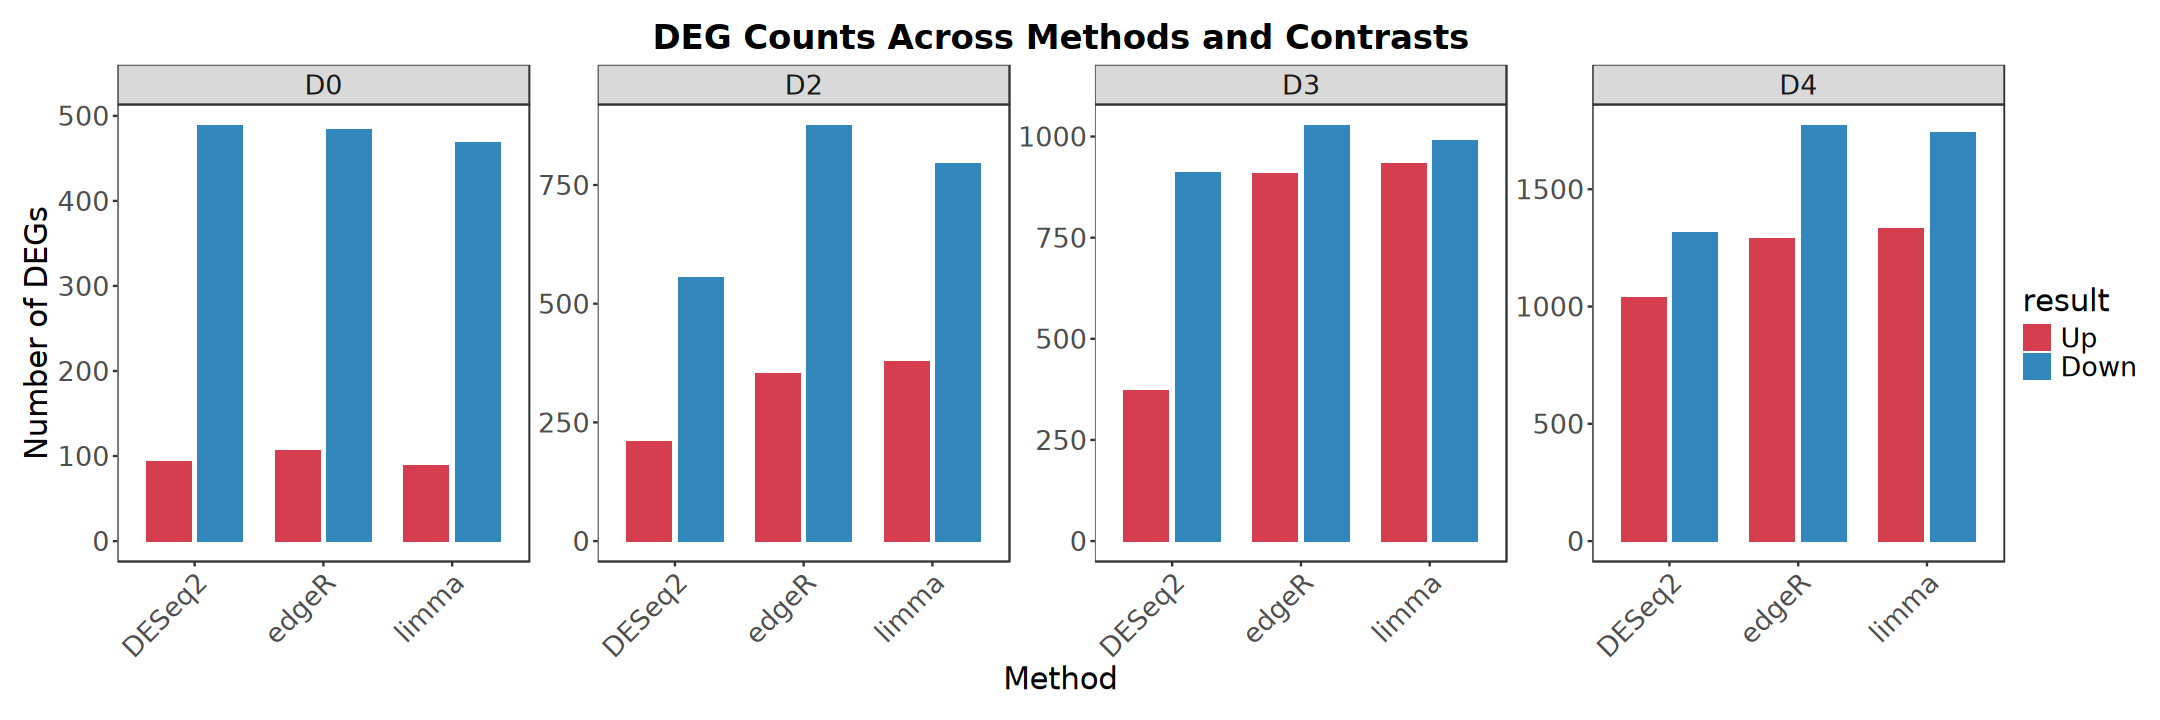

In [82]:
options(repr.plot.width = 18, repr.plot.height = 6)

all_results |> filter(result != "NS") |> 
    dplyr::count(method, contrast, result) |>
    ggplot(aes(x = method, y = n, fill = result)) +
        geom_col(position = position_dodge(width = 0.8), width = 0.7) +
        facet_wrap(~ contrast, nrow = 1, scales = "free_y") +
        scale_fill_manual(
            values = c("Up" = "#D53E4F", "Down" = "#3288BD")) +
        labs(
            title = "DEG Counts Across Methods and Contrasts", 
            x = "Method", y = "Number of DEGs") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            strip.text = element_text(size = 16),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
            axis.text.y = element_text(size = 16))

In [83]:
# ------------------------------------------------------------------------------
# Function: summarize_software_deg_overlaps
#
# Description:
# This function computes and summarizes the overlap composition of DEG sets 
# across different software packages (e.g., DESeq2, edgeR, limma) within a contrast.
# ------------------------------------------------------------------------------
summarize_software_deg_overlaps <- function(prefix, deg_list) {
    sample_names <- grep(
        paste0("^", prefix, "_"), names(deg_list), value = TRUE)
    software_id <- str_replace_all(
        sample_names, paste0(prefix, "_"), "")
    
    comb_levels <- unlist(lapply(seq_along(software_id), function(i) {
        combn(software_id, i, FUN = function(x) 
            paste(x, collapse = "&"), simplify = TRUE)
    }), use.names = FALSE)
    
    current_list <- deg_list[sample_names]
    names(current_list) <- software_id
    
    all_genes <- unique(unlist(current_list))
    
    venn_grid <- expand.grid(rep(list(c(0, 1)), length(software_id))) |> 
        set_names(software_id)
    
    counts_df <- map_dfc(current_list, ~ as.integer(all_genes %in% .x)) |> 
        group_by(across(all_of(software_id))) |> 
        summarise(Counts = n(), .groups = "drop")
    
    venn_grid |> left_join(counts_df, by = software_id) |> 
        mutate(Counts = replace_na(Counts, 0)) |> rowwise() |> 
        mutate(
            Combination = {
                vals <- c_across(all_of(software_id))
                present <- software_id[vals == 1]
                if (length(present) == 0) "none" else 
                paste(present, collapse = "&")
            } |> factor(levels = comb_levels), 
            Group = prefix) |> 
        ungroup() |> 
        filter(Combination != "none") |> 
        dplyr::select(Group, Combination, Counts) |> 
        as.data.frame()
}

In [84]:
deg_list <- all_results |> filter(result != "NS") |> 
    mutate(list_name = paste0(contrast, "_", method)) |> 
    group_by(list_name) |> 
    summarise(genes = list(gene_id)) |> 
    deframe()

deg_overlap_df <- map(contrast_labels, function(con) {
    summarize_software_deg_overlaps(prefix = con, deg_list = deg_list)}) |> 
    list_rbind()

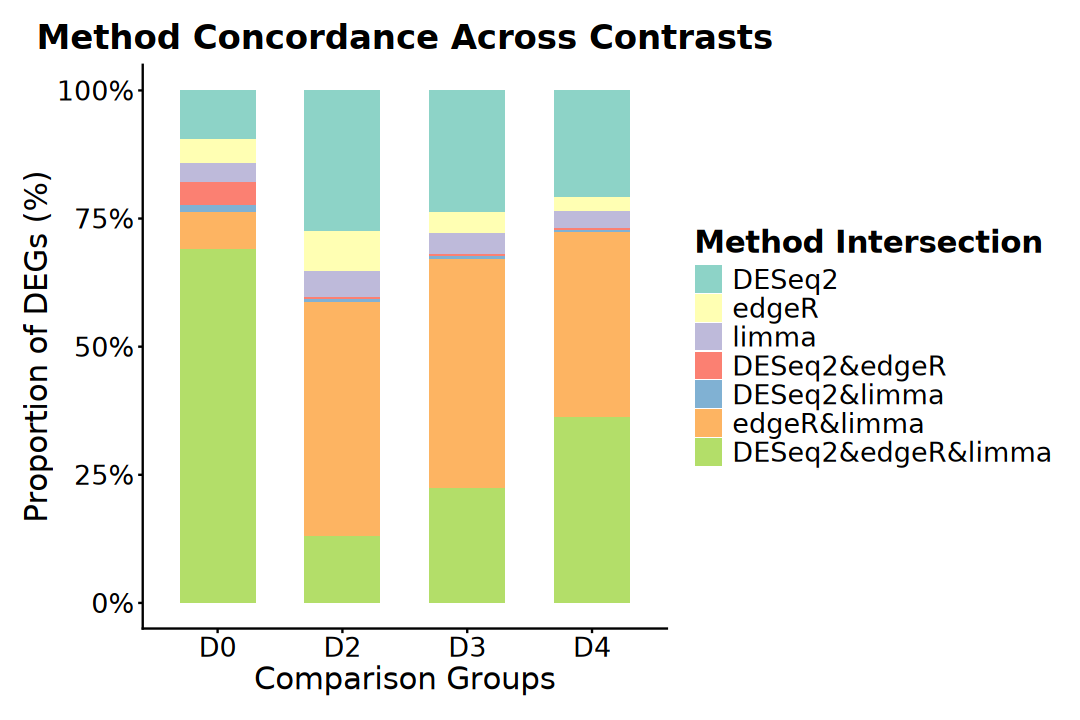

In [85]:
options(repr.plot.width = 9, repr.plot.height = 6)

deg_overlap_df |>
    mutate(Group = str_replace_all(Group, "_", "\n")) |>
    ggplot(aes(x = Group, y = Counts, fill = Combination)) +
        geom_bar(stat = "identity", position = "fill", width = 0.6) +
        scale_y_continuous(labels = scales::percent_format()) + 
        scale_fill_brewer(palette = "Set3") +
        labs(
            title = "Method Concordance Across Contrasts",
            x = "Comparison Groups", 
            y = "Proportion of DEGs (%)",
            fill = "Method Intersection"
        ) +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"), 
            legend.position = "right", 
            legend.title = element_text(size = 18, face = "bold"), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))

## DEGs Visualization

In [86]:
contrast_labels

[1] "D0" "D2" "D3" "D4"

### Multi-group Volcano

In [87]:
deg_df <- bind_rows(deseq2_result_list) |>
    mutate(contrast = factor(contrast, levels = contrast_labels)) |>
    group_by(contrast, result) |>
    arrange(padj, desc(abs(logFC)), .by_group = TRUE) |>
    mutate(
        label = if_else(
            type == "protein_coding" & 
            result %in% c("Up", "Down") & 
            row_number() <= 5, 
            symbol, 
            NA_character_
        )
    ) |>
    ungroup()

table(deg_df$contrast, deg_df$result)

    
        Up  Down    NS
  D0    94   489 16863
  D2   209   555 16682
  D3   372   912 16162
  D4  1038  1315 15093

In [88]:
max_logfc <- deg_df$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

min_padj <- deg_df$padj |> pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 5) * 5)()

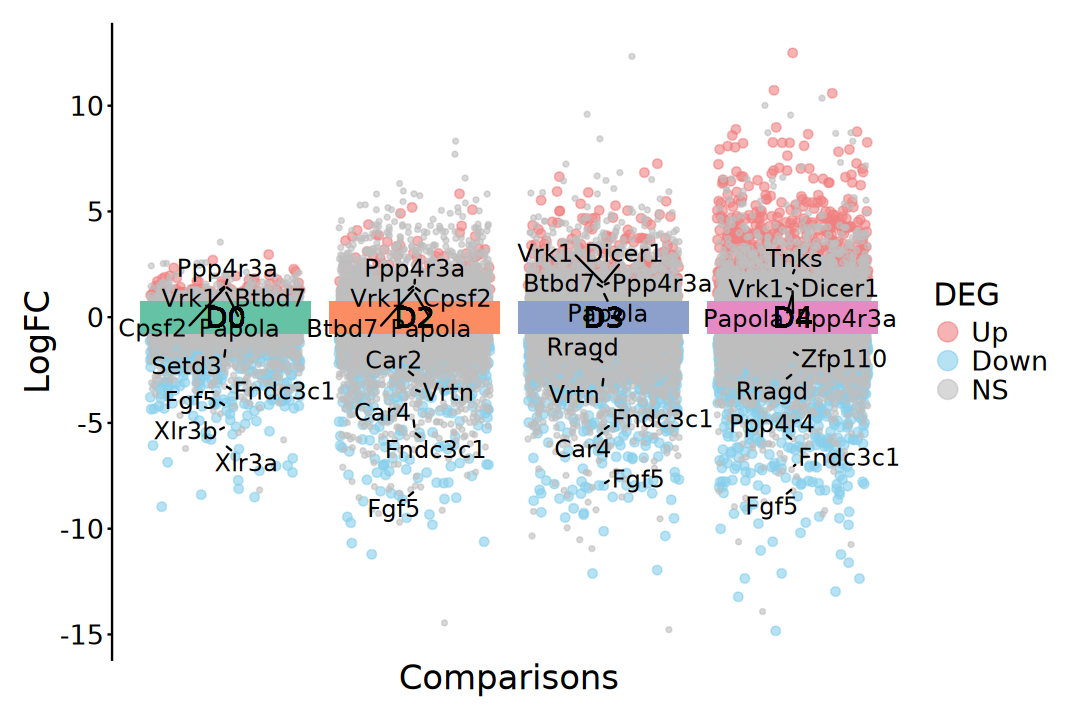

In [89]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(deg_df, aes(x = contrast, y = logFC)) + 
    geom_point(
        aes(color = result, size = result), 
        position = position_jitter(width = 0.4, height = 0), 
        na.rm = TRUE, alpha = 0.6) +
    geom_tile(
        aes(x = contrast, y = 0, fill = contrast), 
        width = 0.9, height = 1.5, show.legend = FALSE) +
    geom_text(
        aes(x = contrast, y = 0, label = contrast), 
        color = "black", size = 6) +
    geom_text_repel(
        aes(label = label), na.rm = TRUE, size = 5, 
        min.segment.length = 0, segment.size = 0.5,
        color = "black", max.overlaps = Inf) +
    scale_fill_brewer(palette = "Set2") + 
    scale_size_manual(
        values = c("Up" = 2, "Down" = 2, "NS" = 1),
        guide = "none") + 
    scale_color_manual(
        name = "DEG",
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    guides(color = guide_legend(override.aes = list(size = 5))) +
    labs(x = "Comparisons", y = "LogFC") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank(),
        axis.line.x = element_blank())

### Heatmap

In [90]:
heatmap_dat <- deg_df |>
    filter(result %in% c("Up", "Down")) |>
    pull(gene_id) |>
    unique() |>
    (\(idx) norm_mat[idx, ])()

In [91]:
ar <- deg_df |> 
    dplyr::select(gene_id, contrast, DEG = result) |>
    pivot_wider(names_from = contrast, values_from = DEG) |> 
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id") |> 
    dplyr::select(all_of(contrast_labels))

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Time, Group)

In [92]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
time_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Time)),
    levels(eSet$Time))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- setNames(
    replicate(length(contrast_labels), deg_colors, simplify = FALSE),
    contrast_labels)

anno_colors <- anno_colors |> 
    append(list(
        Group = group_colors,
        Time = time_colors,
        Replicate = replicate_colors))

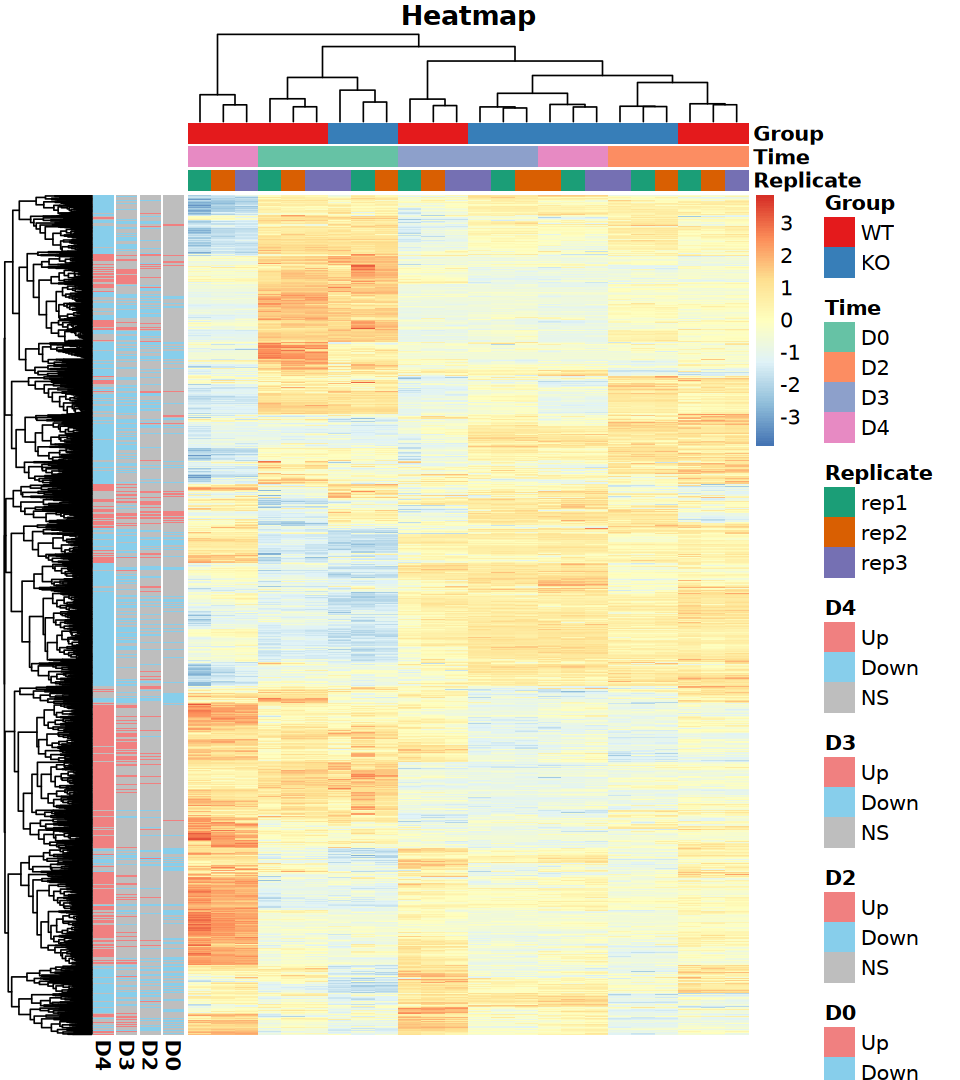

In [93]:
options(repr.plot.width = 8, repr.plot.height = 9)
pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap", fontsize = 12, 
    show_colnames = FALSE, show_rownames = FALSE)

### ComplexHeatmap

In [94]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [95]:
heatmap_dat <- deg_df |>
    filter(result %in% c("Up", "Down")) |>
    pull(gene_id) |>
    unique() |>
    (\(idx) norm_mat[idx, ])()

In [96]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = rev(brewer.pal(n = 3, name = "RdYlBu")))

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
time_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Time)),
    levels(eSet$Time))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [97]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Group, Time, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Group = group_colors, 
        Time = time_colors,
        Replicate = replicate_colors))

In [98]:
ar <- deg_df |> 
    dplyr::select(gene_id, contrast, DEG = result) |>
    pivot_wider(names_from = contrast, values_from = DEG) |> 
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id") |> 
    dplyr::select(all_of(contrast_labels))

anno_colors <- setNames(
    replicate(length(contrast_labels), deg_colors, simplify = FALSE), 
    contrast_labels)

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [99]:
gene_labels <- deg_df |>
    dplyr::filter(!is.na(label)) |>
    dplyr::select(gene_id, label)

mark_rows <- which(rownames(heatmap_dat) %in% gene_labels$gene_id)
mark_labels <- gene_labels$label[
    match(rownames(heatmap_dat)[mark_rows], gene_labels$gene_id)]

right_anno <- rowAnnotation(
    foo = anno_mark(
        at = mark_rows,
        labels = mark_labels,
        labels_gp = gpar(fontsize = 12)))

In [100]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)

lg_group <- Legend(
    title = "Group", labels = levels(dds$Group))

lg_time <- Legend(
    title = "Time", labels = levels(dds$Time))

lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))

lg_deg <- Legend(
    labels = levels(deg_df$result), title = "DEG", 
    legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_time, lg_replicate) |>
    packLegend(direction = "vertical")

In [101]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        # right_annotation = right_anno,
        show_row_names = FALSE, 
        show_column_names = FALSE, 
        use_raster = TRUE)

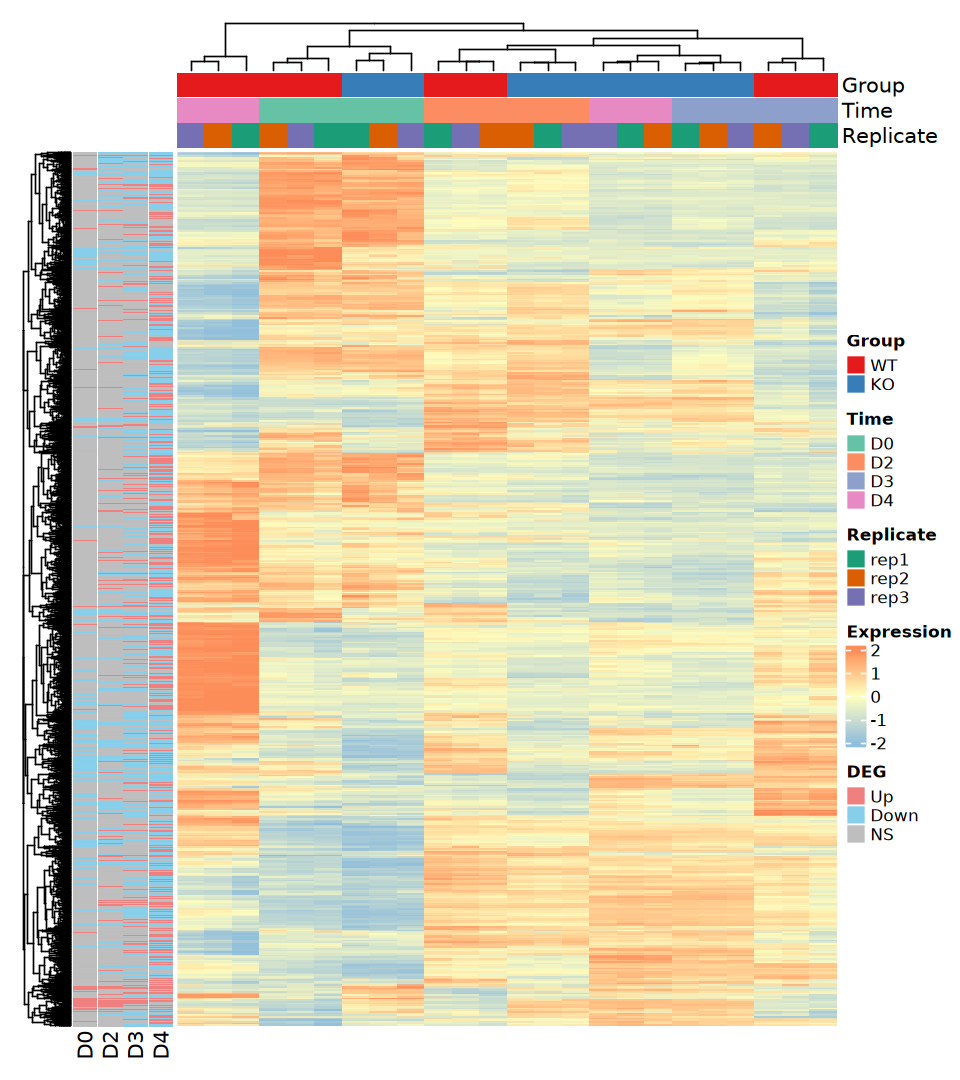

In [102]:
options(repr.plot.width = 8, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE, 
    annotation_legend_list = list(lg_deg), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"), 
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(5, 5, 5, 5), "mm"))

### Sankey Plot

In [103]:
suppressPackageStartupMessages(library(ggalluvial))

In [104]:
sankey_long <- deg_df |> 
    dplyr::select(gene_id, contrast, result) |>
    mutate(result = factor(result, levels = c("Up", "NS", "Down"))) |>
    group_by(gene_id) |>
    filter(any(result != "NS")) |>
    ungroup()

head(sankey_long)

gene_id,contrast,result
<chr>,<fct>,<fct>
ENSMUSG00000041846.15,D0,Up
ENSMUSG00000021111.15,D0,Up
ENSMUSG00000021115.15,D0,Up
ENSMUSG00000041702.7,D0,Up
ENSMUSG00000041781.9,D0,Up
ENSMUSG00000041415.10,D0,Up


In [105]:
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

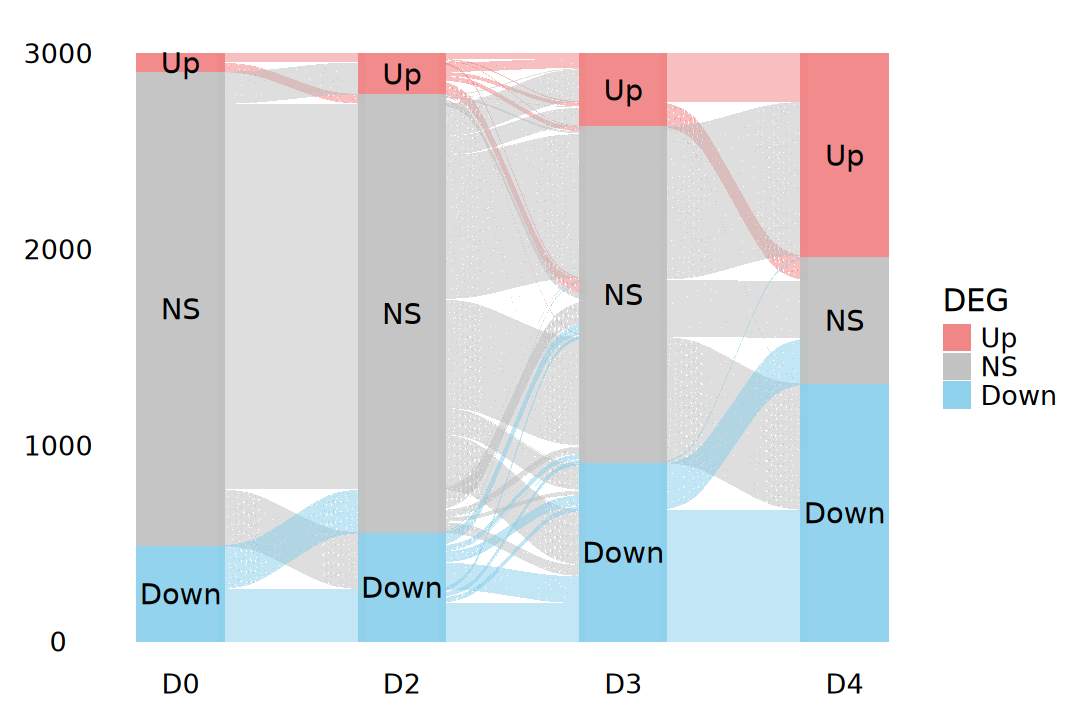

In [106]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(
    sankey_long, aes(
        x = contrast, stratum = result, alluvium = gene_id,
        y = 1, fill = result, label = result)) +
    geom_flow(stat = "alluvium") +
    geom_stratum(width = 0.4, alpha = 0.9, color = NA) +
    geom_text(stat = "stratum", size = 6) +
    scale_x_discrete(limits = contrast_labels, expand = c(.1, .1)) +
    scale_fill_manual(values = deg_colors) +
    labs(x = "Comparisons", y = "Gene count", fill = "DEG") +
    theme_void() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_blank(),
        axis.text = element_text(size = 16))

In [107]:
sankey_wide <- deg_df |> 
    dplyr::select(gene_id, contrast, result) |>
    mutate(result = factor(result, levels = c("Up", "NS", "Down"))) |>
    pivot_wider(names_from = contrast, values_from = result) |> 
    filter(if_any(all_of(contrast_labels), ~ .x != "NS")) |>
    group_by(across(all_of(contrast_labels))) |>
    summarise(Freq = n(), .groups = "drop")

head(sankey_wide)

D0,D2,D3,D4,Freq
<fct>,<fct>,<fct>,<fct>,<int>
Up,Up,Up,Up,26
Up,Up,Up,NS,6
Up,Up,NS,Up,4
Up,Up,NS,NS,10
Up,NS,Up,Up,5
Up,NS,Up,NS,3


Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
"Some strata appear at multiple axes."
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
"Some strata appear at multiple axes."
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
"Some strata appear at multiple axes."


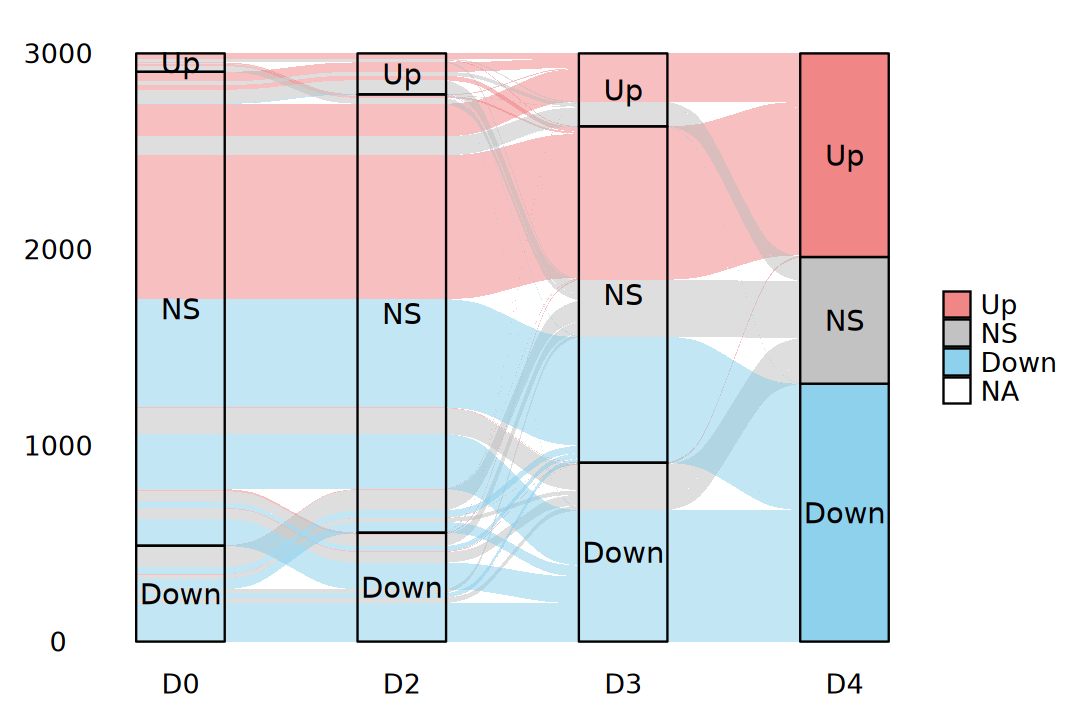

In [108]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(
    sankey_wide, aes(
        axis1 = D0, axis2 = D2, axis3 = D3,
        axis4 = D4, y = Freq, fill = D4)) +
    geom_alluvium(width = 0.4, alpha = 0.5) +
    geom_stratum(width = 0.4, alpha = 0.9, color = "black") +
    geom_text(
        aes(label = after_stat(stratum)), stat = "stratum", size = 6) +
    scale_x_discrete(limits = contrast_labels, expand = c(.1, .1)) +
    scale_fill_manual(values = deg_colors, na.value = NA) +
    labs(
        x = "Comparisons", y = "Gene count", 
        fill = "Status in Primed_vs_Naive") +
    theme_void() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_blank(), 
        legend.text = element_text(size = 16),
        axis.title = element_blank(),
        axis.text = element_text(size = 16))

# 6. Time-course Dynamics

## 1). DEGs: Dynamic Gene Selection

### a). DESeq2 (LRT)

> The likelihood ratio test (LRT) is useful for testing multiple terms at once, for example testing 3 or more levels of a factor at once, or all interactions between two variables. The LRT for count data is conceptually similar to an analysis of variance (ANOVA) calculation in linear regression, except that in the case of the Negative Binomial GLM, we use an analysis of deviance (ANODEV), where the deviance captures the difference in likelihood between a full and a reduced model.
> - Identifies genes with significant expression dynamics across conditions. By comparing the full factors model against a reduced model, LRT filters out invariant baseline features and captures any temporal patterns  (e.g., monotonic or wave-like), serving as a crucial input for clustering.

In [109]:
# Test for the overall main effect of Genotype
design(dds) <- ~ Time + Group

dds <- DESeq(dds, test = "LRT", reduced = ~ Time)

resultsNames(dds)

using pre-existing size factors

estimating dispersions

found already estimated dispersions, replacing these

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



[1] "Intercept"      "Time_D2_vs_D0"  "Time_D3_vs_D0"  "Time_D4_vs_D0" 
[5] "Group_KO_vs_WT"

In [110]:
deseq2_lrt_main_result <- results(dds) |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < 1e-5  ~ "Sig", TRUE ~ "NotSig") |> 
            factor(levels = c("Sig", "NotSig"))) |>
    left_join(
        rowData(dds) |> as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lrt_main_result$result)


   Sig NotSig 
  3525  13921 

In [111]:
# Testing the Genotype × Time Interaction
design(dds) <- ~ Time * Group

dds <- DESeq(dds, test = "LRT", reduced = ~ Time + Group)

resultsNames(dds)

using pre-existing size factors

estimating dispersions

found already estimated dispersions, replacing these

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



[1] "Intercept"      "Time_D2_vs_D0"  "Time_D3_vs_D0"  "Time_D4_vs_D0" 
[5] "Group_KO_vs_WT" "TimeD2.GroupKO" "TimeD3.GroupKO" "TimeD4.GroupKO"

In [112]:
deseq2_lrt_inter_result <- results(dds) |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < 1e-5  ~ "Sig", TRUE ~ "NotSig") |> 
            factor(levels = c("Sig", "NotSig"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lrt_inter_result$result)


   Sig NotSig 
  3174  14272 

### b). edgeR (ANOVA-like)

> ANOVA-like test for any differences. In edgeR, this is done by specifying multiple coefficients to glmQLFTest or glmLRT, when the design matrix includes an intercept term.

In [113]:
# Test for the overall main effect of Group
design <- model.matrix(~ Time + Group, data = dgel$samples)
colnames(design)

[1] "(Intercept)" "TimeD2"      "TimeD3"      "TimeD4"      "GroupKO"

In [114]:
# Estimate dispersion
dgel <- estimateDisp(dgel, design)
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)

coef_idx <- grep("^Group", colnames(design))
qlft <- glmQLFTest(fit, coef = coef_idx)

In [115]:
edger_anova_main_result <- topTags(qlft, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < 1e-5  ~ "Sig", TRUE ~ "NotSig") |>
            factor(levels = c("Sig", "NotSig")))

table(edger_anova_main_result$result)


   Sig NotSig 
  2002  14571 

In [116]:
# Testing the Genotype × Time Interaction
design <- model.matrix(~ Time * Group, data = dgel$samples)
colnames(design)

[1] "(Intercept)"    "TimeD2"         "TimeD3"         "TimeD4"        
[5] "GroupKO"        "TimeD2:GroupKO" "TimeD3:GroupKO" "TimeD4:GroupKO"

In [117]:
# Estimate dispersion
dgel <- estimateDisp(dgel, design)
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)

inter_idx <- grep(":", colnames(design))
qlft <- glmQLFTest(fit, coef = inter_idx)

In [118]:
edger_anova_inter_result <- topTags(qlft, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < 1e-5  ~ "Sig", TRUE ~ "NotSig") |>
            factor(levels = c("Sig", "NotSig")))

table(edger_anova_inter_result$result)


   Sig NotSig 
  1445  15128 

In [119]:
comparison_df <- deseq2_lrt_inter_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, result_deseq2 = result) |> 
    inner_join(
        edger_anova_inter_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, result_edger = result),
        by = c("gene_id"))

cat("\n=========================================\n")
cat("Contrast:", "Stages", "\n")
cat("=========================================\n")
print(table(
    DESeq2 = comparison_df$result_deseq2, 
    edgeR = comparison_df$result_edger))


Contrast: Stages 
        edgeR
DESeq2     Sig NotSig
  Sig     1443   1719
  NotSig     2  13409


In [120]:
genes <- list(
    DEseq2_main = deseq2_lrt_main_result$symbol[deseq2_lrt_main_result$result != "NotSig"], 
    DEseq2_inter = deseq2_lrt_inter_result$symbol[deseq2_lrt_inter_result$result != "NotSig"],
    edgeR_main = edger_anova_main_result$symbol[edger_anova_main_result$result != "NotSig"], 
    edgeR_inter = edger_anova_inter_result$symbol[edger_anova_inter_result$result != "NotSig"])
genes <- lapply(genes, unique)

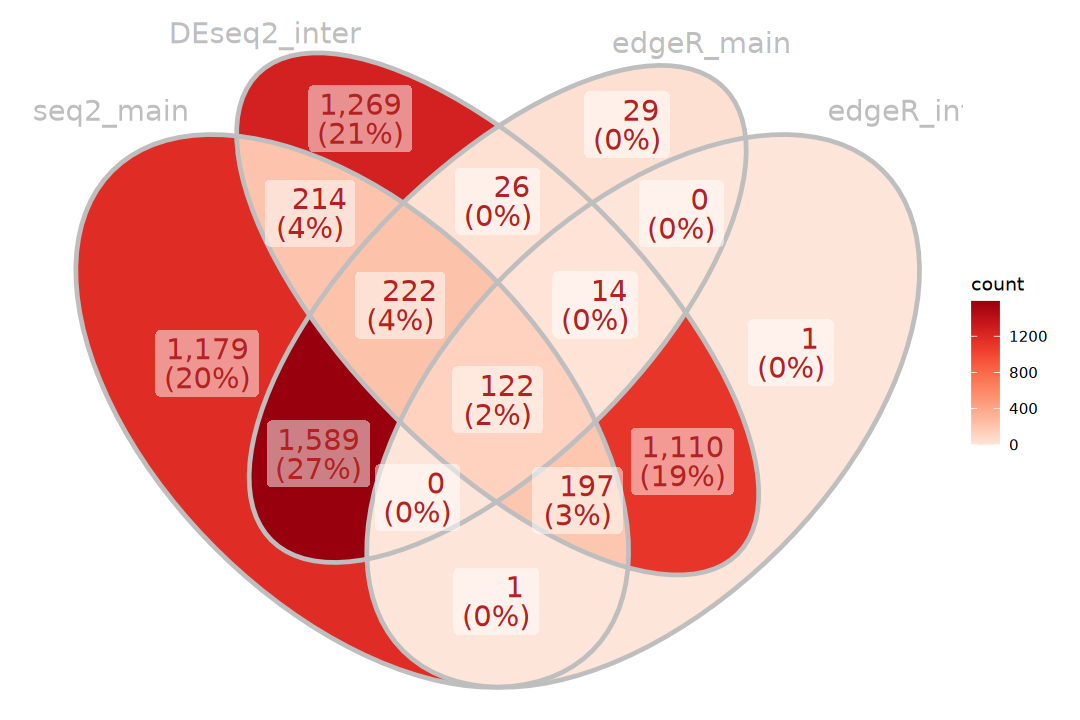

In [121]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggVennDiagram::ggVennDiagram(
    genes, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 6) +
    scale_fill_distiller(palette = "Reds", direction = 1)

## 2). Trend Clustering

> It is recommended to use genes with significant differential expression to enhance computational efficiency. Of course, all genes can also be selected for cluster analysis.

In [122]:
sig_gene_ids <- deseq2_lrt_inter_result |> 
    dplyr::filter(result == "Sig") |> rownames()

message(
    "Number of time-significantly dynamic genes identified by LRT:", 
    length(sig_gene_ids), "\n")

Number of time-significantly dynamic genes identified by LRT:3174




In [123]:
norm_tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()
norm_ltpm <- log2(norm_tpm + 1)
norm_mat <- norm_ltpm[sig_gene_ids, ]

# rld_mat <- assay(rlog(dds, blind = FALSE))
# vst_mat <- assay(vst(dds, blind = FALSE))
# norm_mat <- vst_mat[sig_gene_ids, ]

In [124]:
groups <- eSet$Group
times  <- eSet$Time
group_time_tags <- paste(groups, times, sep = "_")
tag_levels <- unique(group_time_tags) 

norm_mean_mat <- sapply(tag_levels, function(tag) {
    rowMeans(norm_mat[, group_time_tags == tag, drop = FALSE])
})

print(dim(norm_mean_mat))
print(head(norm_mean_mat))

[1] 3174    8
                          WT_D0    WT_D2    WT_D3    WT_D4      KO_D0    KO_D2
ENSMUSG00000051951.5  0.4102107 1.945004 2.555674 2.385808 0.07825093 1.312551
ENSMUSG00000061024.8  7.6812446 7.737658 8.077277 7.468721 7.69892494 7.738713
ENSMUSG00000025915.14 2.3216128 2.334658 2.596771 3.114126 2.28245051 2.383166
ENSMUSG00000016918.15 5.6512368 5.389145 6.192327 5.496073 5.54150044 5.243981
ENSMUSG00000025932.14 1.6868489 1.615846 1.381134 2.560952 1.84165485 1.142177
ENSMUSG00000032769.5  1.0464648 3.706405 3.401846 2.506504 0.84583572 2.330683
                          KO_D3    KO_D4
ENSMUSG00000051951.5  2.1783222 2.734270
ENSMUSG00000061024.8  8.0297819 7.971092
ENSMUSG00000025915.14 2.3532515 2.399258
ENSMUSG00000016918.15 5.4368391 5.617163
ENSMUSG00000025932.14 0.6847396 1.045307
ENSMUSG00000032769.5  2.6409720 2.720745


### a). Mfuzz

> Soft clustering: fuzzy c-means algorithm (of the e1071 package) based on minimization of a weighted square error function.

In [125]:
suppressPackageStartupMessages(library(Mfuzz))

Warning message:
"no DISPLAY variable so Tk is not available"


In [126]:
# Filtering of genes based on their standard deviation
cl_eset <- ExpressionSet(assayData = norm_mean_mat) |>
    filter.std(min.std = 0.5, visu = FALSE) |>
    standardise()
cl_eset

1289 genes excluded.


ExpressionSet (storageMode: lockedEnvironment)
assayData: 1885 features, 8 samples 
  element names: exprs 
protocolData: none
phenoData: none
featureData: none
experimentData: use 'experimentData(object)'
Annotation:  

In [127]:
# Estimate for optimal fuzzifier m
m_val <- mestimate(cl_eset)
message(paste0("fuzzifier m: ", m_val))

set.seed(123)
cl_mfuzz <- mfuzz(cl_eset, c = 6, m = 1.5)
cl_mfuzz$cluster |> table()

fuzzifier m: 1.46056797855108




  1   2   3   4   5   6 
385 328 373 272 197 330 

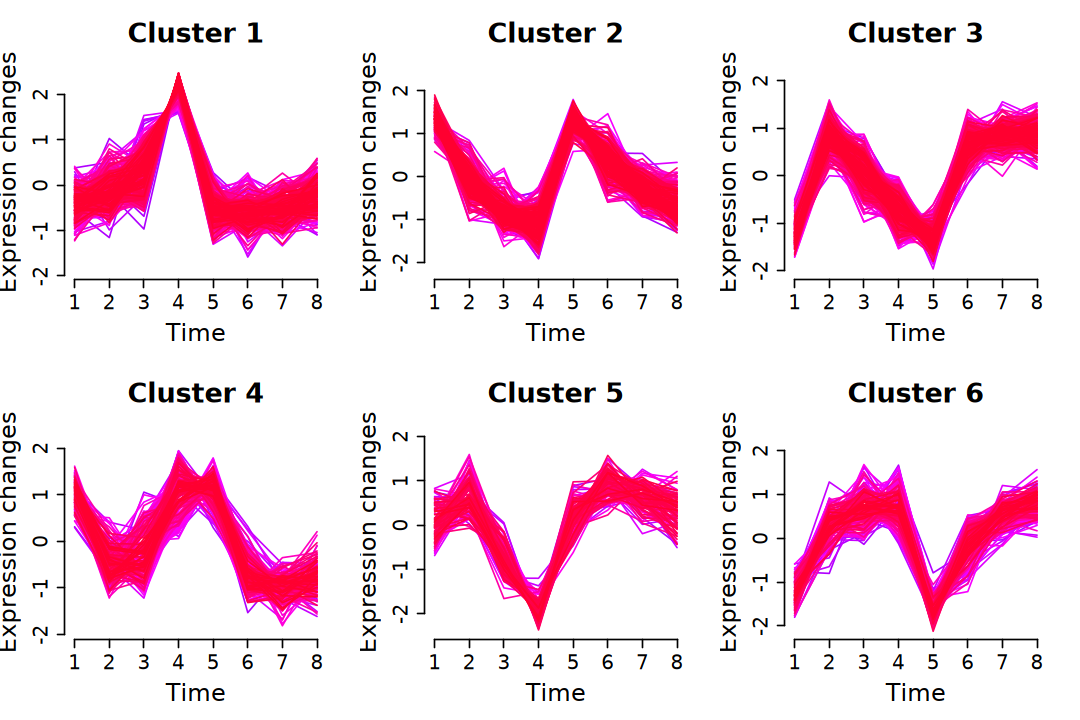

In [128]:
options(repr.plot.width = 9, repr.plot.height = 6)

mfuzz.plot2(
    cl_eset, cl = cl_mfuzz, mfrow = c(2, 3), 
    min.mem = 0.8, x11 = FALSE, cex.main = 2,
    cex.lab = 1.8, cex.axis = 1.5)

### b). TCseq

In [129]:
suppressPackageStartupMessages(library(TCseq))

Warning message:
"replacing previous import 'e1071::element' by 'ggplot2::element' when loading 'TCseq'"


In [130]:
norm_mean_filtered_tpm <- norm_mean_mat[rowSds(norm_mean_mat) >= 0.5, ]

set.seed(123)
cl_tcseq <- timeclust(
    norm_mean_filtered_tpm, algo = "cm", k = 6, standardize = TRUE)
cl_tcseq@cluster |> table()


  1   2   3   4   5   6 
379 328 366 276 205 331 

Warning message:
"The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the TCseq package.
  Please report the issue to the authors."


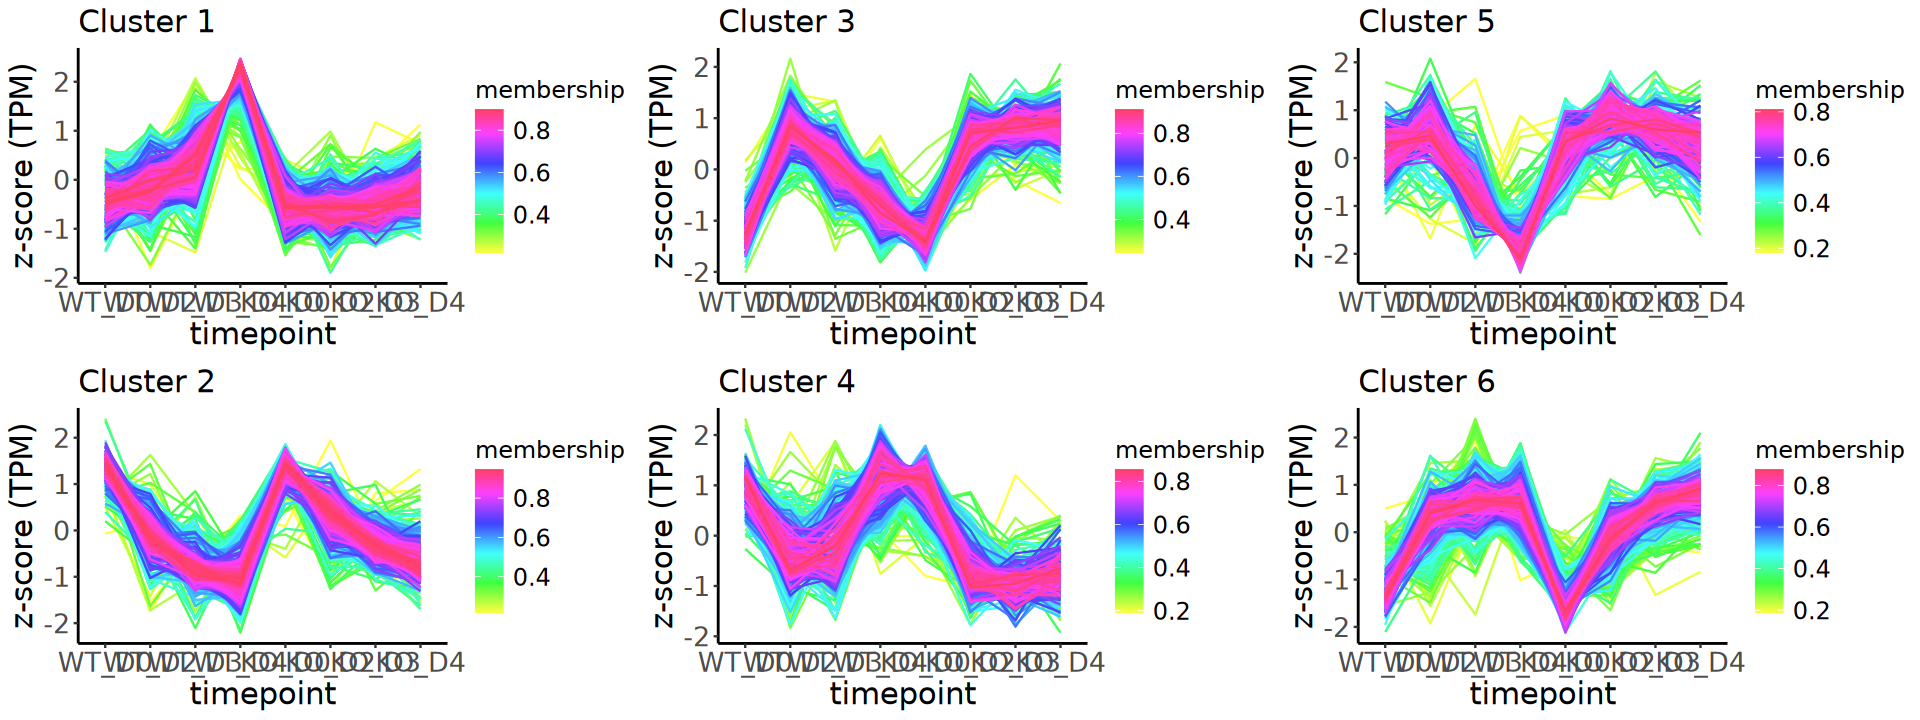

In [131]:
options(repr.plot.width = 16, repr.plot.height = 6)

p <- timeclustplot(cl_tcseq, value = "z-score (TPM)", cols = 3)

## 3). Regression

### a). maSigPro

> maSigPro follows a two-step regression strategy to find genes with significant temporal expression changes and significant differences between experimental groups.

In [132]:
suppressPackageStartupMessages(library(maSigPro))

In [133]:
design_df <- colData(eSet) |> as.data.frame() |> 
    mutate(
        Time = as.integer(gsub("^D", "", Time)), 
        Replicate = as.integer(Replicate), 
        Count = 1) |> 
    rownames_to_column(var = "sample") |>
    pivot_wider(
        id_cols = c(sample, Time, Replicate), 
        names_from = Group, values_from = Count, 
        values_fill = list(Count = 0)) |>
    column_to_rownames(var = "sample") |>
    dplyr::select(Time, Replicate, levels(eSet$Group))

head(design_df)

,Time,Replicate,WT,KO
,<int>,<int>,<dbl>,<dbl>
WT_D0_rep1,0,1,1,0
WT_D0_rep2,0,2,1,0
WT_D0_rep3,0,3,1,0
WT_D2_rep1,2,1,1,0
WT_D2_rep2,2,2,1,0
WT_D2_rep3,2,3,1,0


In [134]:
# Defining the regression model
# degree = time points - 1
# Usually, a polynomial of degree 2 is more than enough to model the gene expression, 
# although a degree 3 may be appropriate in experacimental setups with a big number of
# time points.
design <- make.design.matrix(design_df, degree = 3)

In [135]:
# dgel <- estimateGLMCommonDisp(dgel, design = design)
# phi <- dgel$common.dispersion
# theta <- 1/phi
1 / dgel$common.dispersion

[1] 130.3827

In [136]:
# DEseq2
# norm_counts <- counts(dds, normalized = TRUE)

# # edgeR
# eff_lib_size <- dgel$samples$lib.size * dgel$samples$norm.factors
# norm_counts <- t(t(dgel$counts) / eff_lib_size) * mean(eff_lib_size)

# TPM
norm_counts <- norm_ltpm

In [137]:
# Performs regression analysis for each gene to identify significant ones.
fit <- p.vector(
    norm_counts, design, counts = TRUE, 
    theta = 130, Q = 0.05, MT.adjust = "BH")

[1] "fitting  gene 100 out of 17446"
[1] "fitting  gene 200 out of 17446"
[1] "fitting  gene 300 out of 17446"
[1] "fitting  gene 400 out of 17446"
[1] "fitting  gene 500 out of 17446"
[1] "fitting  gene 600 out of 17446"
[1] "fitting  gene 700 out of 17446"
[1] "fitting  gene 800 out of 17446"
[1] "fitting  gene 900 out of 17446"
[1] "fitting  gene 1000 out of 17446"
[1] "fitting  gene 1100 out of 17446"
[1] "fitting  gene 1200 out of 17446"
[1] "fitting  gene 1300 out of 17446"
[1] "fitting  gene 1400 out of 17446"
[1] "fitting  gene 1500 out of 17446"
[1] "fitting  gene 1600 out of 17446"
[1] "fitting  gene 1700 out of 17446"
[1] "fitting  gene 1800 out of 17446"
[1] "fitting  gene 1900 out of 17446"
[1] "fitting  gene 2000 out of 17446"
[1] "fitting  gene 2100 out of 17446"
[1] "fitting  gene 2200 out of 17446"
[1] "fitting  gene 2300 out of 17446"
[1] "fitting  gene 2400 out of 17446"
[1] "fitting  gene 2500 out of 17446"
[1] "fitting  gene 2600 out of 17446"
[1] "fitting  gene 27

In [138]:
print(fit$i)

[1] 16344


In [139]:
# Selects the best regression model for each gene using stepwise regression.
tstep <- T.fit(fit, step.method = "backward", alfa = 0.05)

[1] "fitting  gene 100 out of 16344"
[1] "fitting  gene 200 out of 16344"
[1] "fitting  gene 300 out of 16344"
[1] "fitting  gene 400 out of 16344"
[1] "fitting  gene 500 out of 16344"
[1] "fitting  gene 600 out of 16344"
[1] "fitting  gene 700 out of 16344"
[1] "fitting  gene 800 out of 16344"
[1] "fitting  gene 900 out of 16344"
[1] "fitting  gene 1000 out of 16344"
[1] "fitting  gene 1100 out of 16344"
[1] "fitting  gene 1200 out of 16344"
[1] "fitting  gene 1300 out of 16344"
[1] "fitting  gene 1400 out of 16344"
[1] "fitting  gene 1500 out of 16344"
[1] "fitting  gene 1600 out of 16344"
[1] "fitting  gene 1700 out of 16344"
[1] "fitting  gene 1800 out of 16344"
[1] "fitting  gene 1900 out of 16344"
[1] "fitting  gene 2000 out of 16344"
[1] "fitting  gene 2100 out of 16344"
[1] "fitting  gene 2200 out of 16344"
[1] "fitting  gene 2300 out of 16344"
[1] "fitting  gene 2400 out of 16344"
[1] "fitting  gene 2500 out of 16344"
[1] "fitting  gene 2600 out of 16344"
[1] "fitting  gene 27

In [140]:
sigs <- get.siggenes(tstep, rsq = 0.6, vars = "all")

In [141]:
summary(sigs)
sig_gene_ids <- sigs$summary

cat("Number of significant time-varying genes:", length(sig_gene_ids), "\n")

          Length Class  Mode     
sig.genes     7  -none- list     
summary   11870  -none- character

Number of significant time-varying genes: 11870 


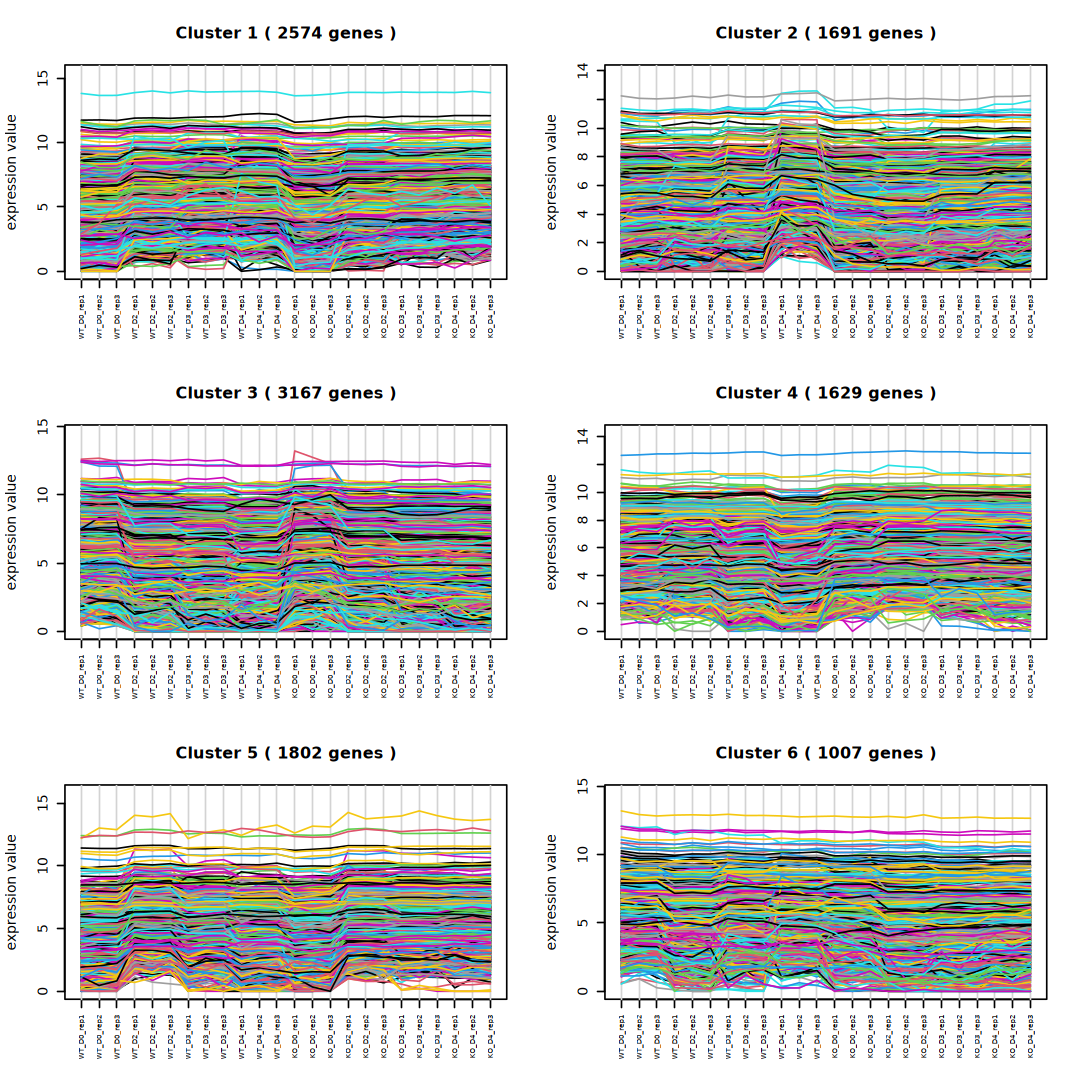

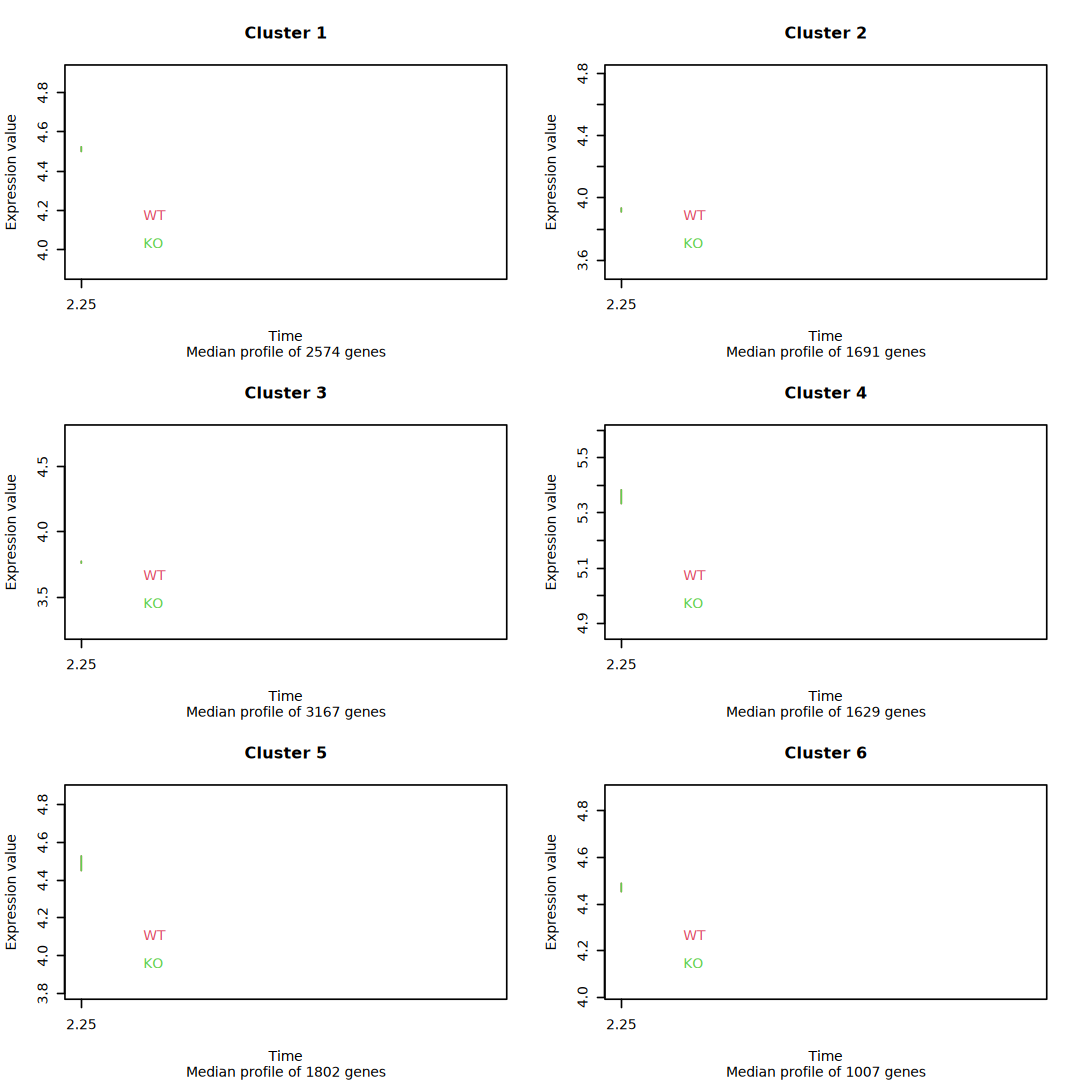

In [142]:
options(repr.plot.width = 9, repr.plot.height = 9)
cl_masigpro <- see.genes(sigs$sig.genes, k = 6)

In [143]:
cl_masigpro$cut |> table()


   1    2    3    4    5    6 
2574 1691 3167 1629 1802 1007 

## Clustering Evaluation

### Adjusted Rand Index, ARI

In [144]:
suppressPackageStartupMessages(library(mclust))

In [145]:
gene_lists <- list(
    names(cl_mfuzz$cluster),
    names(cl_tcseq@cluster),
    names(cl_masigpro$cut))

common_genes <- Reduce(intersect, gene_lists)

vector_mfuzz    <- cl_mfuzz$cluster[common_genes]
vector_tcseq    <- cl_tcseq@cluster[common_genes]
vector_masigpro <- cl_masigpro$cut[common_genes]

In [146]:
ari_mfuzz_tcseq    <- adjustedRandIndex(vector_mfuzz, vector_tcseq)
ari_mfuzz_masigpro <- adjustedRandIndex(vector_mfuzz, vector_masigpro)
ari_tcseq_masigpro <- adjustedRandIndex(vector_tcseq, vector_masigpro)

cat("ARI (Mfuzz vs tcseq):", ari_mfuzz_tcseq, "\n")
cat("ARI (Mfuzz vs maSigPro):", ari_mfuzz_masigpro, "\n")
cat("ARI (tcseq vs maSigPro):", ari_tcseq_masigpro, "\n")

ARI (Mfuzz vs tcseq): 0.9378118 
ARI (Mfuzz vs maSigPro): 0.5799222 
ARI (tcseq vs maSigPro): 0.5831653 


### Jaccard Similarity

In [147]:
table_match <- table(vector_mfuzz, vector_tcseq)

jaccard_matrix <- matrix(
    0, nrow=nrow(table_match), ncol=ncol(table_match),
    dimnames=list(
        paste0("Mfuzz_C", rownames(table_match)), 
        paste0("TCseq_C", colnames(table_match))))

for(i in 1:nrow(table_match)) {
    for(j in 1:ncol(table_match)) {
        intersection <- table_match[i, j]
        union_size <- sum(vector_mfuzz == rownames(table_match)[i]) + 
            sum(vector_tcseq == colnames(table_match)[j]) - intersection
        jaccard_matrix[i, j] <- intersection / union_size
    }
}

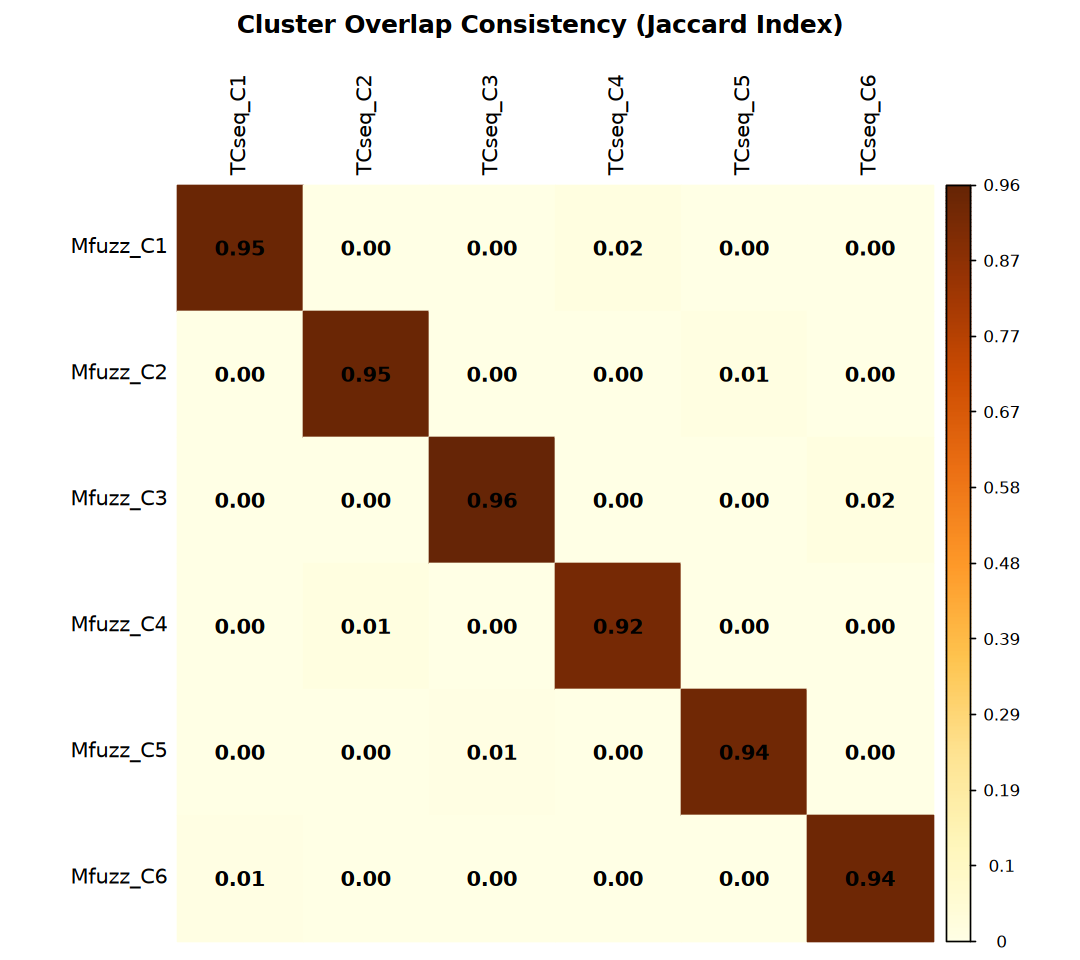

In [148]:
options(repr.plot.width = 9, repr.plot.height = 8)
corrplot::corrplot(
    jaccard_matrix, is.corr = FALSE, method = "color", 
    addCoef.col = "black", tl.col = "black", 
    title = "Cluster Overlap Consistency (Jaccard Index)", 
    mar = c(0,0,2,0))

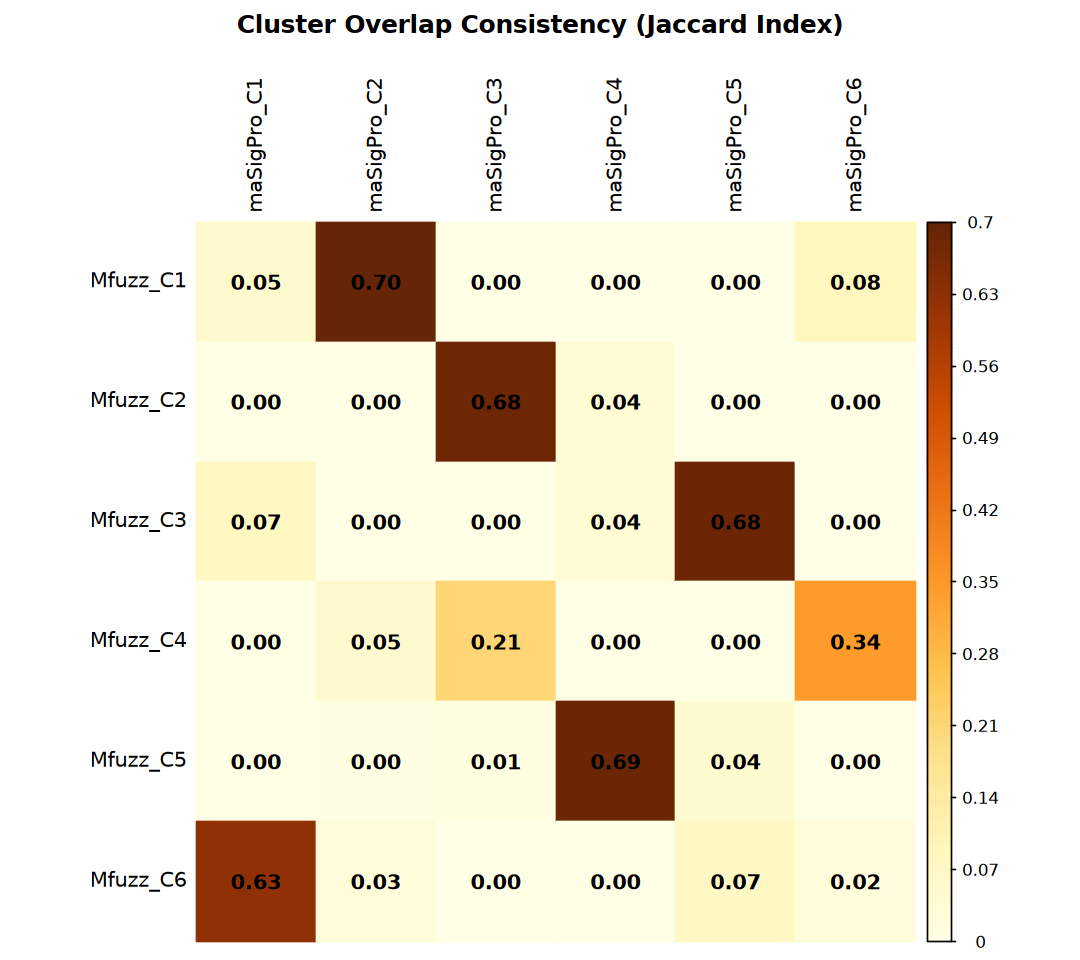

In [149]:
table_match <- table(vector_mfuzz, vector_masigpro)

jaccard_matrix <- matrix(
    0, nrow=nrow(table_match), ncol=ncol(table_match),
    dimnames=list(
        paste0("Mfuzz_C", rownames(table_match)), 
        paste0("maSigPro_C", colnames(table_match))))

for(i in 1:nrow(table_match)) {
    for(j in 1:ncol(table_match)) {
        intersection <- table_match[i, j]
        union_size <- sum(vector_mfuzz == rownames(table_match)[i]) + 
            sum(vector_masigpro == colnames(table_match)[j]) - intersection
        jaccard_matrix[i, j] <- intersection / union_size
    }
}

options(repr.plot.width = 9, repr.plot.height = 8)
corrplot::corrplot(
    jaccard_matrix, is.corr = FALSE, method = "color", 
    addCoef.col = "black", tl.col = "black", 
    title = "Cluster Overlap Consistency (Jaccard Index)", 
    mar = c(0,0,2,0))

## Clustering Visualization

### Lineplot

In [150]:
norm_mat <- log2(tpm + 1)

In [151]:
norm_expr_df <- norm_mat |> as.data.frame() |>
    rownames_to_column(var = "gene_id") |>
    pivot_longer(cols = -gene_id, names_to = "sample", values_to = "value")

In [152]:
plot_lineplot <- function(cluster, expression, coldata, group, time, method) {
    data.frame(cluster = cluster) |>
        rownames_to_column(var = "gene_id") |>
        mutate(cluster = factor(paste0("cluster", cluster))) |>
        add_count(cluster, name = "count") |>
        left_join(expression, by = "gene_id") |>
        left_join(coldata, by = "sample") |>
        group_by(
            across(all_of(group)), across(all_of(time)), 
            Replicate, cluster, count) |>
        summarize(
            median_value = median(value, na.rm = TRUE), 
            .groups = "drop") |>
        mutate(
            cluster_label = paste0(cluster, " (n=", count, ")"),
            cluster_label = factor(cluster_label)) |>
        ungroup() |>
    ggplot(aes(
        x = .data[[time]], y = median_value, 
        color = .data[[group]], group = .data[[group]])) +
        stat_summary(
            fun = mean, geom = "line", linewidth = 1, alpha = 0.8) +
        stat_summary(
            fun.data = mean_se, geom = "errorbar", width = 0.1) +
        facet_wrap(~ cluster_label, nrow = 1) + 
        scale_x_discrete(expand = expansion(mult = c(0.1, 0.1))) +
        scale_y_continuous(expand = expansion(mult = c(0.1, 0.1))) +
        scale_color_brewer(palette = "Dark2") +
        labs(
            title = paste0("Time-course: ", method), 
            color = "Cluster", x = NULL, y = "Median Expression") +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            strip.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16),
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16))
}

In [153]:
coldata <- colData(eSet) |> as.data.frame() |> 
    rownames_to_column(var = "sample")

p1 <- plot_lineplot(
    cluster = cl_mfuzz$cluster, expression = norm_expr_df, 
    coldata = coldata, group = "Group", time = "Time", method = "Mfuzz")
p2 <- plot_lineplot(
    cluster = cl_tcseq@cluster, expression = norm_expr_df, 
    coldata = coldata, group = "Group", time = "Time", method = "TCseq")
p3 <- plot_lineplot(
    cluster = cl_masigpro$cut, expression = norm_expr_df, 
    coldata = coldata, group = "Group", time = "Time", method = "maSigPro")

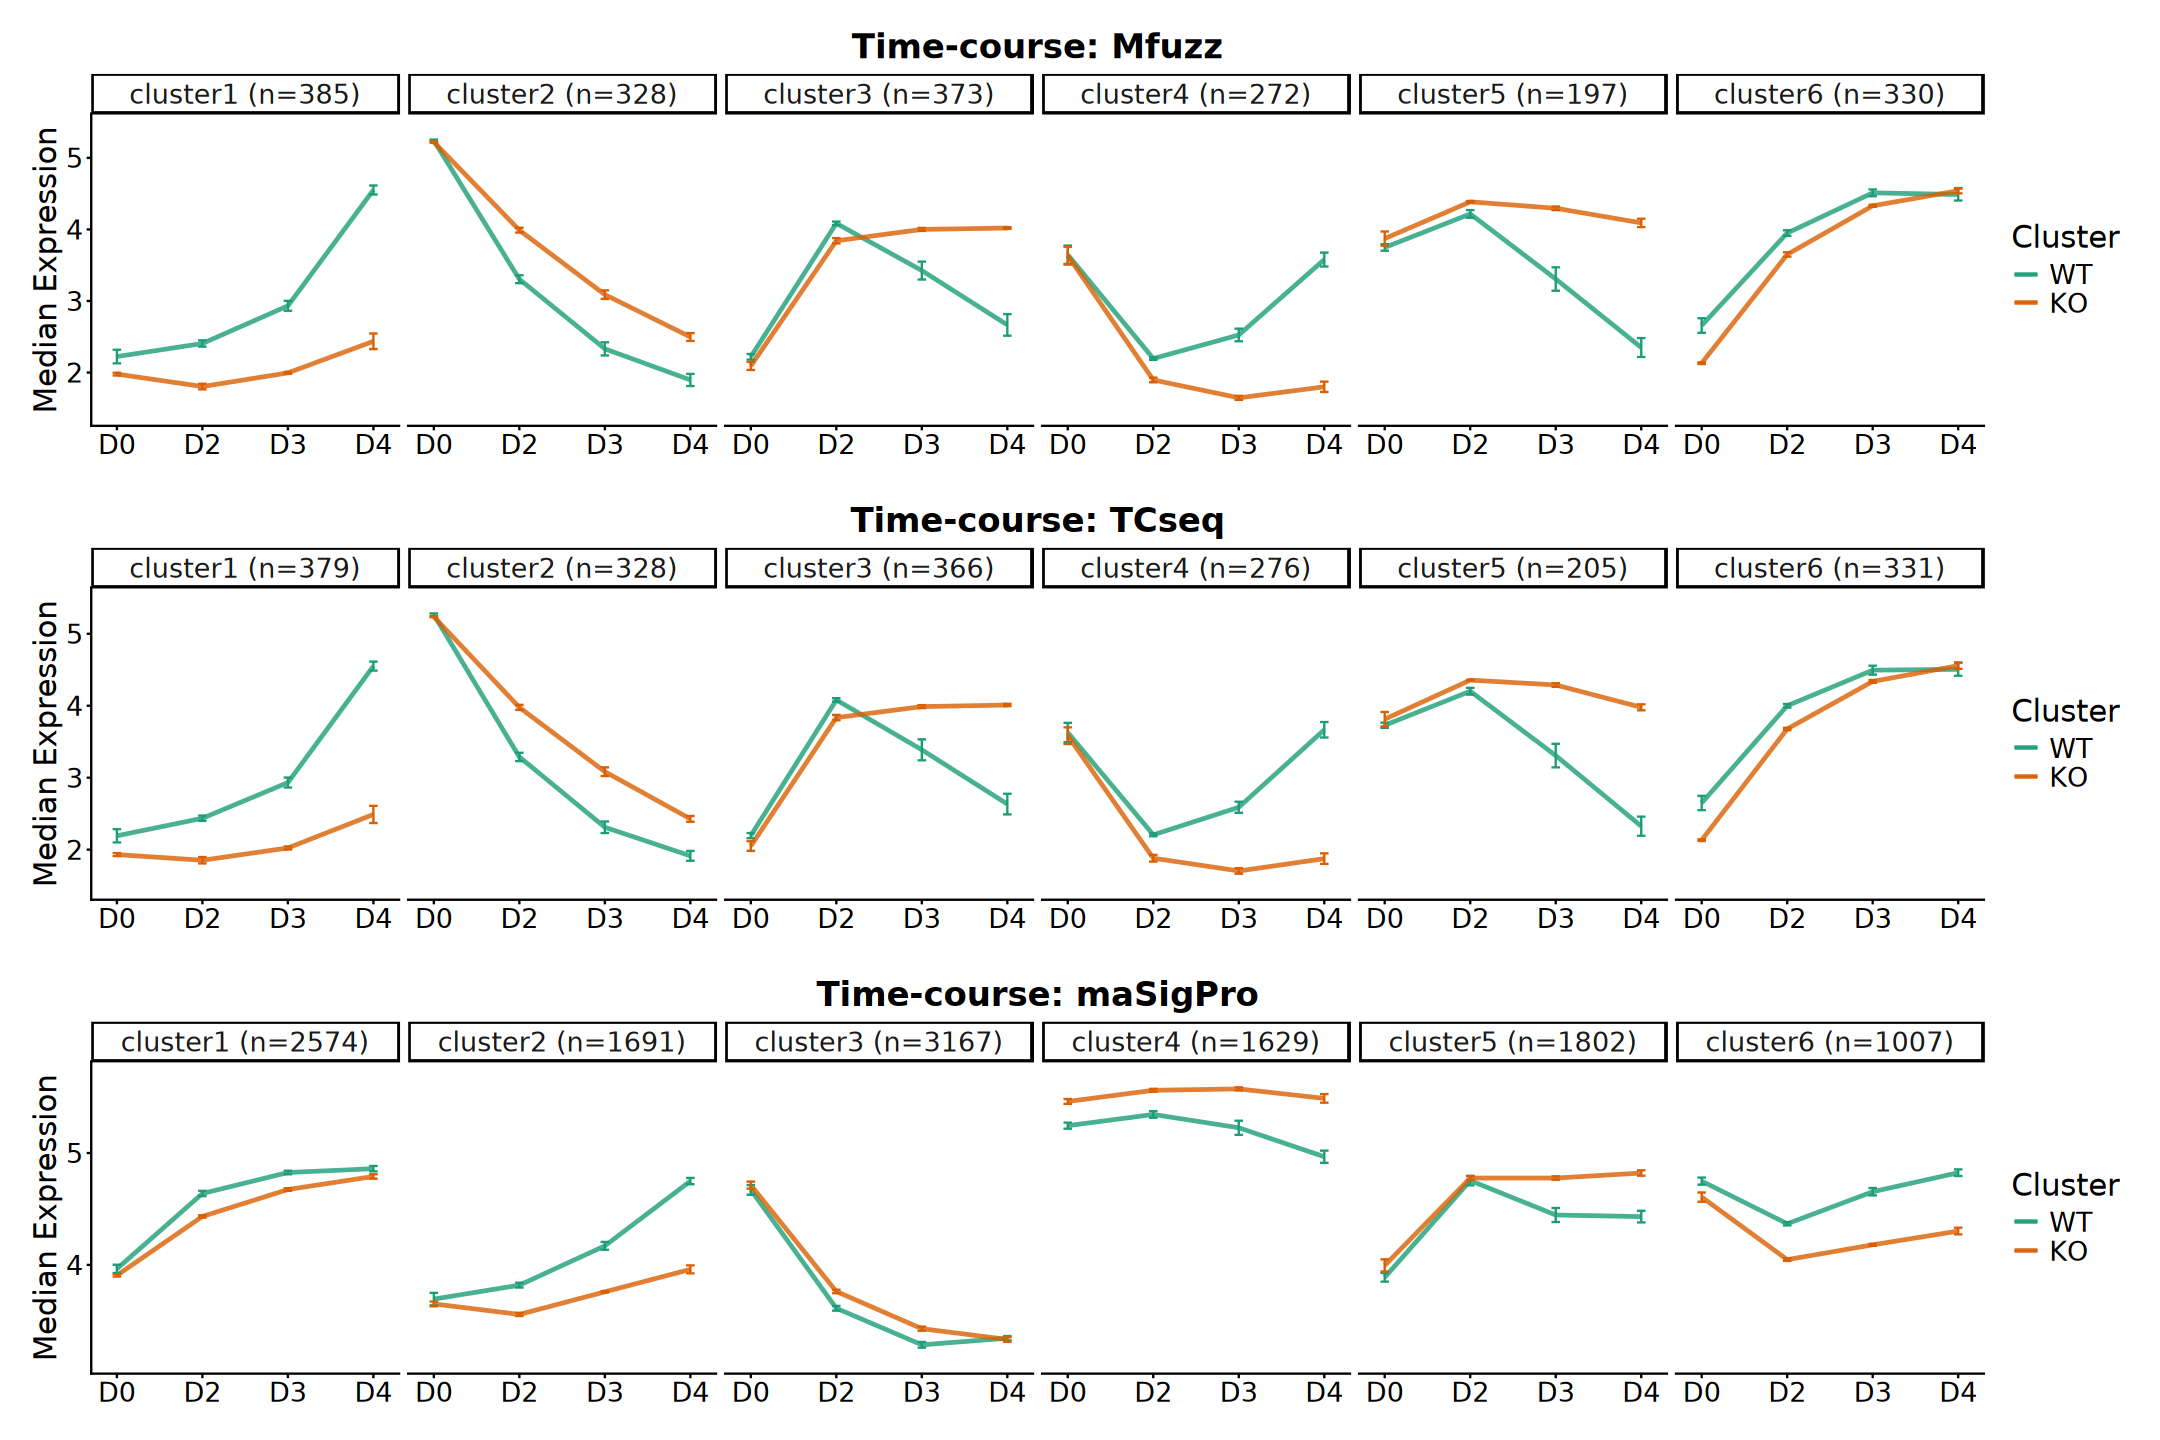

In [154]:
options(repr.plot.width = 18, repr.plot.height = 12)
p1 / p2 / p3

### Heatmap

In [155]:
ac <- colData(dds) |> 
    as.data.frame() |>
    dplyr::select(Replicate, Time, Group)

In [156]:
ar <- cl_mfuzz$cluster |> data.frame(Cluster = _) |>
    mutate(Cluster = factor(paste0("cluster", Cluster))) |>
    arrange(Cluster)

In [157]:
heatmap_dat <- norm_mat[rownames(ar), ]

In [158]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
time_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Time)),
    levels(eSet$Time))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Group = group_colors,
    Time = time_colors,
    Replicate = replicate_colors)

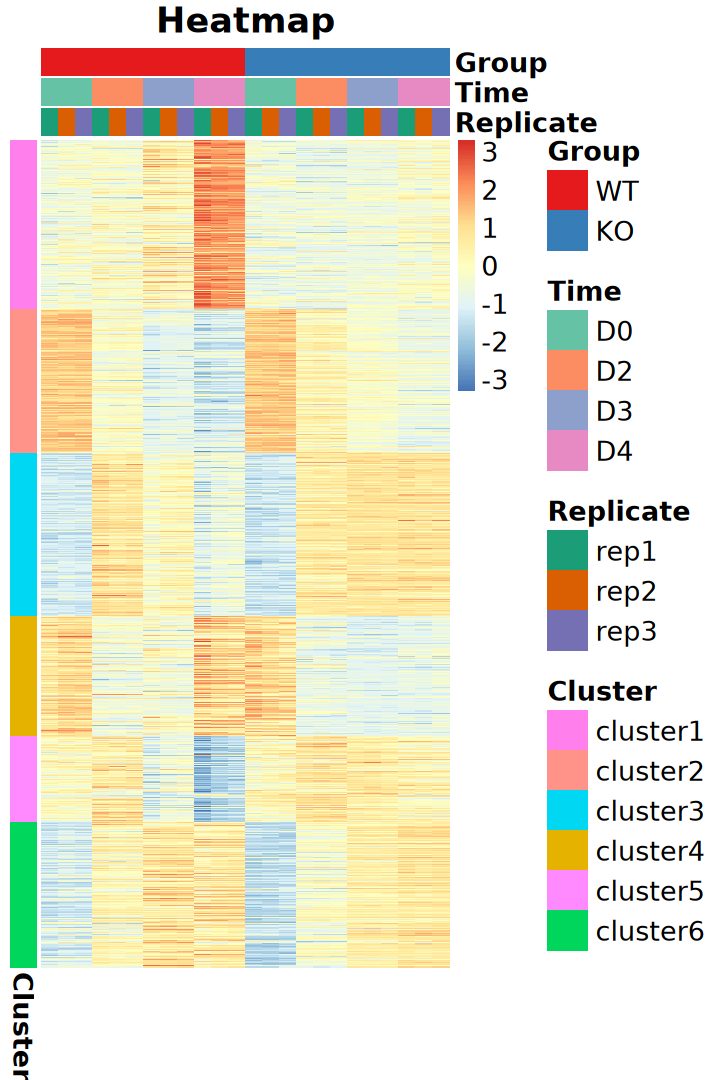

In [159]:
options(repr.plot.width = 6, repr.plot.height = 9)
pheatmap::pheatmap(
    heatmap_dat, scale = "row", 
    cluster_rows = FALSE, cluster_cols = FALSE,
    annotation_row = ar, annotation_col = ac,
    annotation_colors = anno_colors,
    main = "Heatmap", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 7. Gene Function Analysis

## 1). ORA

> Over-Representation Analysis

### Part 1

In [160]:
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [161]:
add_ENTREZID <- function(
    res, col, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = FALSE) {
    
    gene_ids <- res[[col]]

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }
    
    return(res)
}

In [162]:
deg_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deg_df$contrast, deg_df$result)

    
        Up  Down    NS
  D0    94   489 16863
  D2   209   555 16682
  D3   372   912 16162
  D4  1038  1315 15093

In [163]:
deg_df <- add_ENTREZID(
    deg_df, "gene_id", org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"9.76% of input gene IDs are fail to map..."


In [164]:
deg_types <- c("Up", "Down")

genes_list <- crossing(comp = contrast_labels, deg = deg_types) |>
    pmap(~ deg_df$symbol[deg_df$result == .y & deg_df$contrast == .x]) |>
    set_names(paste(
        contrast_labels, rep(deg_types, each = length(contrast_labels)), 
        sep = "_")) |>
    lapply(unique)

In [165]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = unique(deg_df$SYMBOL), 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [166]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,D0_Up,BP,GO:0007369,gastrulation,27/407,197/14511,0.13705584,4.886529,9.329842,8.447144e-12,3.164300e-08,2.786668e-08,27
2,D0_Up,BP,GO:0003002,regionalization,39/407,410/14511,0.09512195,3.391436,8.344217,2.341705e-11,4.386014e-08,3.862581e-08,39
3,D0_Up,BP,GO:0007389,pattern specification process,40/407,452/14511,0.08849558,3.155183,7.907438,1.177858e-10,1.470752e-07,1.295231e-07,40
4,D0_Up,BP,GO:0009952,anterior/posterior pattern specification,26/407,213/14511,0.12206573,4.352078,8.371939,2.841671e-10,2.661224e-07,2.343630e-07,26
5,D0_Up,BP,GO:0001704,formation of primary germ layer,20/407,127/14511,0.15748031,5.614734,8.872959,3.668044e-10,2.748099e-07,2.420137e-07,20
6,D0_Up,BP,GO:0007492,endoderm development,16/407,90/14511,0.17777778,6.338411,8.629693,3.519919e-09,2.105524e-06,1.854248e-06,16


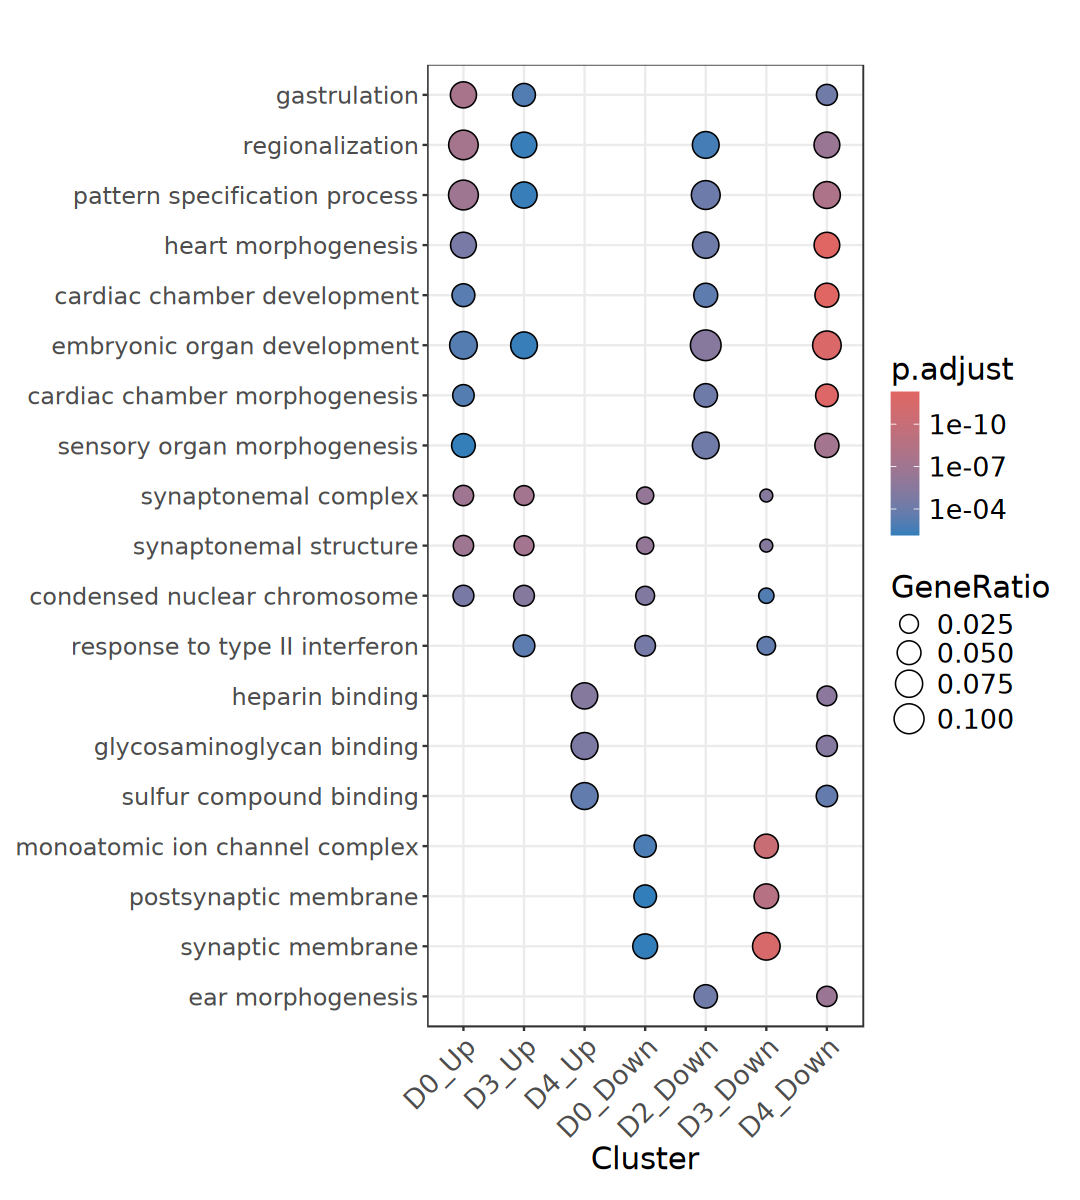

In [167]:
options(repr.plot.width = 9, repr.plot.height = 10)

dotplot(ego_compare, showCategory = 3, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [168]:
deg_types <- c("Up", "Down")

genes_list <- crossing(comp = contrast_labels, deg = deg_types) |>
    pmap(~ deg_df$ENTREZID[deg_df$result == .y & deg_df$contrast == .x]) |>
    set_names(paste(
        contrast_labels, rep(deg_types, each = length(contrast_labels)), 
        sep = "_")) |>
    lapply(unique)

In [169]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, 
    universe = unique(deg_df$ENTREZID), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

In [170]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,D0_Up,Human Diseases,Cancer: specific types,mmu05217,Basal cell carcinoma,9/187,60/6569,0.15000000,5.269251,5.686292,4.271372e-05,0.0061544906,0.0055876296,9
2,D0_Up,Environmental Information Processing,Signaling molecules and interaction,mmu04512,ECM-receptor interaction,10/187,76/6569,0.13157895,4.622150,5.436377,5.128742e-05,0.0061544906,0.0055876296,10
3,D0_Up,Human Diseases,Infectious disease: viral,mmu05165,Human papillomavirus infection,21/187,302/6569,0.06953642,2.442699,4.393478,1.222622e-04,0.0088338466,0.0080202028,21
4,D0_Up,Environmental Information Processing,Signaling molecules and interaction,mmu04519,Cadherin signaling,21/187,306/6569,0.06862745,2.410769,4.325978,1.472308e-04,0.0088338466,0.0080202028,21
5,D0_Down,Organismal Systems,Development and regeneration,mmu04382,Cornified envelope formation,21/395,104/6569,0.20192308,3.358057,6.130820,6.711457e-07,0.0001953034,0.0001907467,21
6,D0_Down,Environmental Information Processing,Signaling molecules and interaction,mmu04514,Cell adhesion molecule (CAM) interaction,21/395,112/6569,0.18750000,3.118196,5.718625,2.398428e-06,0.0003489713,0.0003408292,21


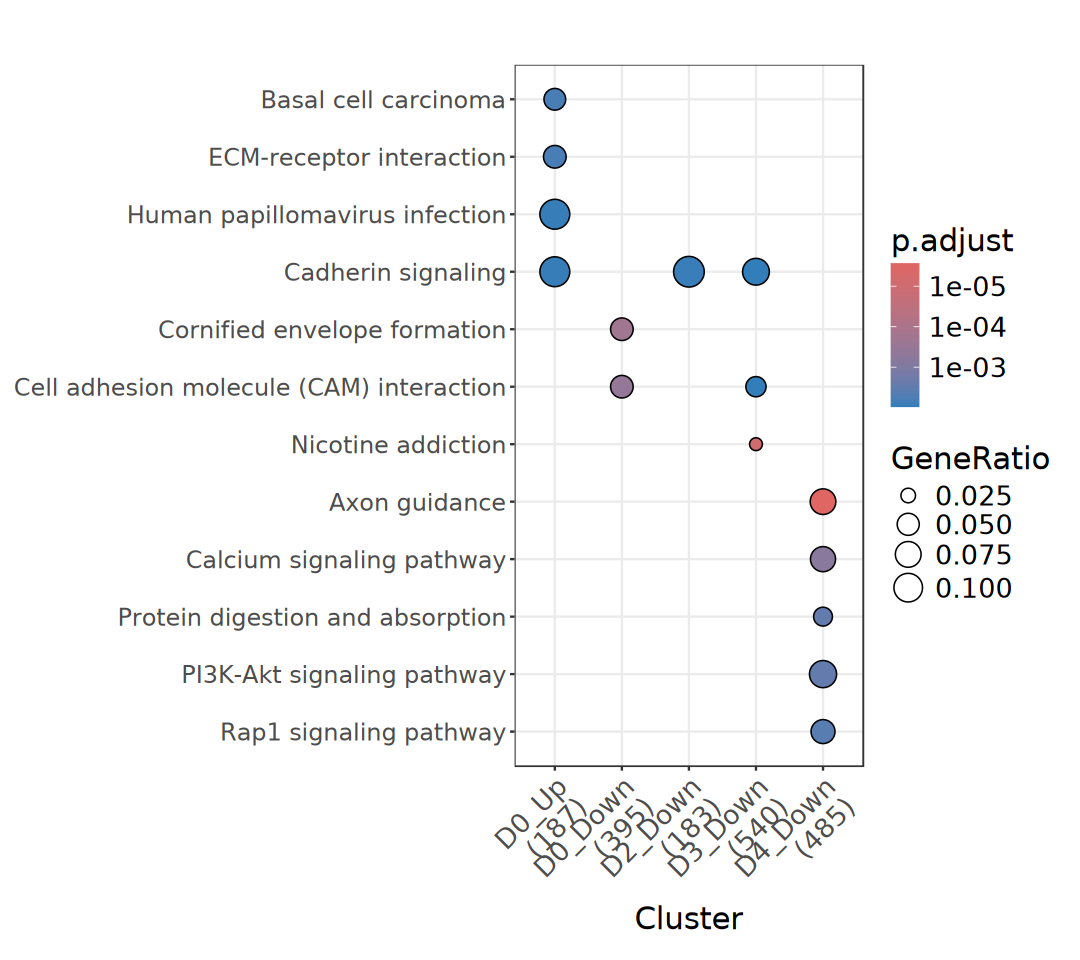

In [171]:
options(repr.plot.width = 9, repr.plot.height = 8)

dotplot(ekegg_compare, showCategory = 5, label_format = 40) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

### Part 2

In [172]:
gene_map <- bitr(
    rowData(dds)$symbol, OrgDb = org.Mm.eg.db, fromType = "SYMBOL", 
    toType = c("ENTREZID"), drop = FALSE)

'select()' returned 1:1 mapping between keys and columns

Warning message in bitr(rowData(dds)$symbol, OrgDb = org.Mm.eg.db, fromType = "SYMBOL", :
"7.19% of input gene IDs are fail to map..."


In [173]:
membership_df <- cl_mfuzz$membership |> 
    as.data.frame() |> 
    rownames_to_column(var = "gene_id") |> 
    pivot_longer(cols = -gene_id, names_to = "cluster", values_to = "membership")

In [174]:
cluster_df <- cl_mfuzz$cluster |> 
    data.frame(cluster = _) |>
    mutate(cluster = as.character(cluster)) |>
    rownames_to_column(var = "gene_id") |>
    left_join(membership_df, by = c("gene_id", "cluster")) |>
    filter(membership > 0.6) |>
    left_join(
        rowData(dds) |> as.data.frame() |> 
        dplyr::select(symbol, type) |>
        rownames_to_column("gene_id"), 
        by = "gene_id") |>
    left_join(gene_map, by = c("symbol" = "SYMBOL"))

table(cluster_df$cluster)
head(cluster_df)


  1   2   3   4   5   6 
319 282 319 217 153 236 

,gene_id,cluster,membership,symbol,type,ENTREZID
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
1,ENSMUSG00000051951.5,6,0.9934135,Xkr4,protein_coding,497097
2,ENSMUSG00000025932.14,4,0.7132450,Eya1,protein_coding,14048
3,ENSMUSG00000032769.5,6,0.6590833,Trpa1,protein_coding,277328
4,ENSMUSG00000042686.5,6,0.7553333,Jph1,protein_coding,57339
5,ENSMUSG00000026121.13,6,0.8925098,Sema4c,protein_coding,20353
6,ENSMUSG00000046337.17,2,0.6283879,Fam178b,protein_coding,381337


In [175]:
# membership_df <- cl_tcseq@membership |> 
#     as.data.frame() |> 
#     rownames_to_column(var = "gene_id") |> 
#     pivot_longer(cols = -gene_id, names_to = "cluster", values_to = "membership")

# cluster_df <- cl_tcseq@cluster |> 
#     data.frame(cluster = _) |>
#     mutate(cluster = as.character(cluster)) |>
#     rownames_to_column(var = "gene_id") |>
#     left_join(membership_df, by = c("gene_id", "cluster")) |>
#     filter(membership > 0.6) |>
#     left_join(
#         rowData(dds) |> as.data.frame() |> 
#         dplyr::select(symbol, type) |>
#         rownames_to_column("gene_id"), 
#         by = "gene_id") |>
#     left_join(gene_map, by = c("gene_id" = "ENSEMBL"))

# table(cluster_df$cluster)

In [176]:
gene_list <- split(cluster_df$symbol, cluster_df$cluster)

In [177]:
ego_cluster_compare <- compareCluster(
    geneCluster = gene_list, fun = enrichGO,
    universe = rowData(dds)$symbol, 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [178]:
ego_cluster_compare |> dplyr::select(-geneID) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,1,BP,GO:0030510,regulation of BMP signaling pathway,14/298,92/14248,0.15217391,7.275751,8.826166,6.588019e-09,2.211743e-05,1.967954e-05,14
2,1,BP,GO:0071772,response to BMP,17/298,152/14248,0.11184211,5.347404,7.875653,1.918806e-08,2.211743e-05,1.967954e-05,17
3,1,BP,GO:0071773,cellular response to BMP stimulus,17/298,152/14248,0.11184211,5.347404,7.875653,1.918806e-08,2.211743e-05,1.967954e-05,17
4,1,BP,GO:0030509,BMP signaling pathway,16/298,142/14248,0.11267606,5.387277,7.679271,4.551736e-08,3.934975e-05,3.501243e-05,16
5,1,BP,GO:0072001,renal system development,25/298,344/14248,0.07267442,3.474715,6.790743,6.471565e-08,4.475735e-05,3.982397e-05,25
6,1,BP,GO:0060485,mesenchyme development,23/298,311/14248,0.07395498,3.535942,6.608723,1.622028e-07,9.348290e-05,8.317875e-05,23


In [179]:
gene_list <- split(cluster_df$ENTREZID, cluster_df$cluster)

In [180]:
ekegg_cluster_compare <- compareCluster(
    geneCluster = gene_list, fun = enrichKEGG, 
    universe = unique(gene_map$ENTREZID), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

In [181]:
ekegg_cluster_compare |> dplyr::select(-geneID) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,1,Environmental Information Processing,Signal transduction,mmu04310,Wnt signaling pathway,15/141,164/6441,0.09146341,4.178127,6.167360,2.450140e-06,0.0005929339,0.0005777173,15
2,1,Organismal Systems,Development and regeneration,mmu04360,Axon guidance,14/141,173/6441,0.08092486,3.696716,5.378684,2.224642e-05,0.0026918168,0.0026227358,14
3,1,Human Diseases,Endocrine and metabolic disease,mmu04950,Maturity onset diabetes of the young,5/141,19/6441,0.26315789,12.021277,7.197071,4.252350e-05,0.0034302290,0.0033421979,5


### Clustered Heatmap

In [182]:
norm_mat <- log2(tpm + 1)

#### 1). Heatmap-ggplot2

In [183]:
plot_df <- norm_mat |> t() |> scale() |> t() |> 
    as.data.frame() |> 
    rownames_to_column("gene_id") |>
    pivot_longer(cols = -gene_id, names_to = "sample", values_to = "expression") |>
    right_join(cluster_df, by = "gene_id") |>
    mutate(
        sample = factor(sample, levels = colnames(dds)), 
        cluster = as.factor(cluster)) |>
    arrange(cluster, membership, sample, expression)

head(plot_df)

gene_id,sample,expression,cluster,membership,symbol,type,ENTREZID
<chr>,<fct>,<dbl>,<fct>,<dbl>,<chr>,<chr>,<chr>
ENSMUSG00000045658.16,WT_D0_rep1,-0.5883146,1,0.6000475,Pid1,protein_coding,98496
ENSMUSG00000045658.16,WT_D0_rep2,-0.3734808,1,0.6000475,Pid1,protein_coding,98496
ENSMUSG00000045658.16,WT_D0_rep3,-0.5838093,1,0.6000475,Pid1,protein_coding,98496
ENSMUSG00000045658.16,WT_D2_rep1,-0.7784215,1,0.6000475,Pid1,protein_coding,98496
ENSMUSG00000045658.16,WT_D2_rep2,-0.7639000,1,0.6000475,Pid1,protein_coding,98496
ENSMUSG00000045658.16,WT_D2_rep3,-1.0769625,1,0.6000475,Pid1,protein_coding,98496


In [184]:
line_plot <- ggplot(plot_df, aes(x = sample, y = expression)) +
    geom_path(
        aes(group = gene_id, color = membership),
        linewidth = 0.5, alpha = 0.5) +
    scale_color_distiller(
        palette = "RdYlBu", limits = c(0.6, 1), 
        breaks = seq(0.6, 1, 0.2)) +
    scale_y_continuous(breaks = c(-2, 0, 2)) + 
    facet_wrap(
        ~ cluster, ncol = 1, strip.position = "left",
        labeller = "label_both") + 
    coord_cartesian(clip = "off") + 
    theme_classic() +
    theme(
        panel.border = element_rect(color = "grey", fill = NA, linewidth = 1),
        strip.text = element_text(size = 16),
        strip.background = element_rect(fill = brewer.pal(6, "Set3"), colour = NA),
        legend.title = element_text(size = 18, vjust = 1),
        legend.text = element_text(size = 16),
        legend.position = "top", 
        axis.title = element_blank(),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank())

In [185]:
heatmap_plot <- ggplot(plot_df, aes(x = sample, y = gene_id)) +
    geom_tile(aes(fill = expression)) +
    scale_fill_distiller(palette = "RdYlBu", breaks = c(-2, 0, 2)) +
    facet_wrap(~ cluster, ncol = 1, scales = "free_y") + 
    theme_void() +
    theme(
        panel.border = element_rect(color = "grey", fill = NA, linewidth = 1),
        strip.text = element_blank(),
        legend.title = element_text(size = 18, vjust = 1),
        legend.text = element_text(size = 16),
        legend.position = "top", 
        axis.title = element_blank(),
        axis.text.x = element_blank(),
        axis.text.y = element_blank(),
        axis.ticks.y = element_blank())

In [186]:
strip_plot <- colData(dds) |> as.data.frame() |> 
    rownames_to_column("sample") |>
    mutate(sample = factor(sample, levels = colnames(dds))) |>
    ggplot(aes(x = sample)) +
        geom_tile(aes(y = 1, color = Time, fill = Time), width = 1, height = 1) +
        geom_tile(aes(y = 2, color = Group, fill = Group), width = 1, height = 1) +
        scale_x_discrete(expand = c(0, 0)) +
        # scale_y_continuous(breaks = c(1, 2), labels = c("Group", "Time"), expand = c(0, 0)) +
        scale_color_brewer(palette = "Set3") +
        scale_fill_brewer(palette = "Set3") +
        theme_void() +
        theme(
            legend.title = element_text(size = 18, vjust = 1),
            legend.text = element_text(size = 16))

In [187]:
go_annotations <- ego_cluster_compare |> as.data.frame() |> 
    dplyr::select(Cluster, ONTOLOGY, ID, Description, p.adjust, Count) |>
    mutate(
        ONTOLOGY = factor(ONTOLOGY, levels = c("BP", "MF", "CC")),
        GO_term = paste0(Description, " (", ONTOLOGY, ")")) |>
    group_by(Cluster) |> 
    arrange(ONTOLOGY, p.adjust, .by_group = TRUE) |>
    slice_head(n = 5) |>
    summarise(GO_term = paste(GO_term, collapse = "\n")) |>
    left_join(
        plot_df |> group_by(cluster) |> 
            summarise(y_pos = mean(as.numeric(factor(gene_id)))), 
        by = c("Cluster" = "cluster"))

In [188]:
annotation_plot <- ggplot(go_annotations, aes(x = 0, y = y_pos)) +
    geom_text(
        aes(color = GO_term, label = GO_term), 
        hjust = 0, size = 4, show.legend = FALSE) +
    facet_wrap(~ Cluster, ncol = 1, scales = "free_y") +
    scale_color_brewer(palette = "Dark2") + 
    xlim(c(0, 1)) +
    theme_test() + 
    theme(
        strip.text = element_blank(),
        axis.title = element_blank(),
        axis.text = element_blank(),
        axis.ticks = element_blank())

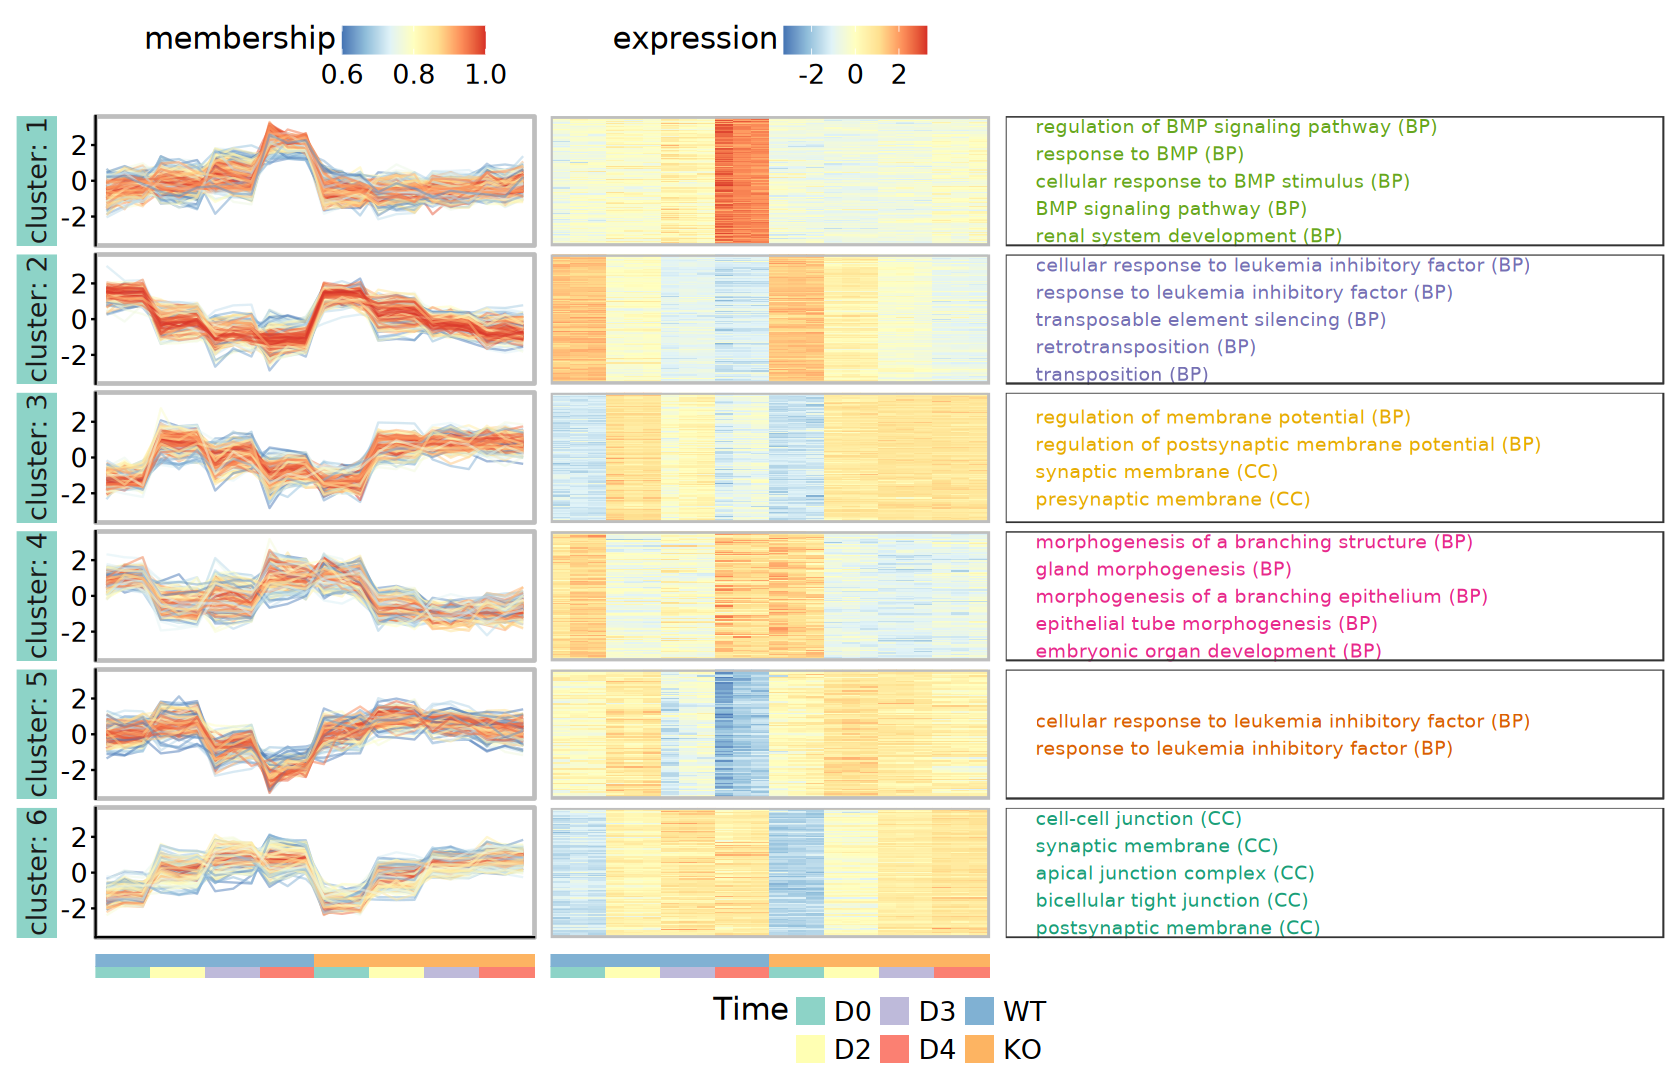

In [189]:
options(repr.plot.width = 14, repr.plot.height = 9)
top_row <- line_plot + heatmap_plot + annotation_plot +
    plot_layout(widths = c(2, 2, 3))
bottom_row <- strip_plot + strip_plot + plot_spacer() +
    plot_layout(widths = c(2, 2, 3), guides = "collect") & 
    theme(legend.position = "bottom")

top_row / bottom_row + 
    plot_layout(heights = c(1, 0.03)) &
    theme(
        plot.margin = margin(5, 5, 5, 5),
        strip.placement = "outside")

#### 2). ComplexHeatmap

In [190]:
cluster_df <- cluster_df |>
    mutate(cluster = factor(paste0("cluster", cluster)))

In [191]:
ac <- colData(dds) |> 
    as.data.frame() |>
    dplyr::select(Group, Time, Replicate)

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
time_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Time)),
    levels(dds$Time))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Group = group_colors,
        Time = time_colors,
        Replicate = replicate_colors))

In [192]:
ar <- cluster_df |> 
    dplyr::select(gene_id, Cluster = cluster) |>
    column_to_rownames("gene_id") |>
    arrange(Cluster)

cluster_colors <- setNames(
    scales::brewer_pal(palette = "Set3")(nlevels(ar$Cluster)),
    levels(ar$Cluster))

left_anno <- rowAnnotation(
    df = ar, col = list(Cluster = cluster_colors),
    show_legend = FALSE)

In [193]:
heatmap_dat <- norm_mat[rownames(ar), ]

heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

In [194]:
gene_labels <- cluster_df |>
    filter(type == "protein_coding") |>
    group_by(cluster) |>
    slice_max(order_by = membership, n = 5, with_ties = FALSE) |>
    ungroup()

mark_rows <- which(rownames(heatmap_dat) %in% gene_labels$gene_id)
mark_labels <- gene_labels$symbol[
    match(rownames(heatmap_dat)[mark_rows], 
    gene_labels$gene_id)]

right_anno <- rowAnnotation(
    foo = anno_mark(
        at = mark_rows,
        labels = mark_labels,
        labels_gp = gpar(fontsize = 12)),
    width = unit(2.5, "cm"))

In [195]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)

lg_group <- Legend(
    title = "Group", labels = levels(dds$Group))

lg_time <- Legend(
    title = "Time", labels = levels(dds$Time))

lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))

lg_cluster <- Legend(
    labels = levels(ar$Cluster), title = "Cluster", 
    legend_gp = gpar(fill = cluster_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [196]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        show_row_names = FALSE, show_column_names = FALSE, 
        use_raster = TRUE)

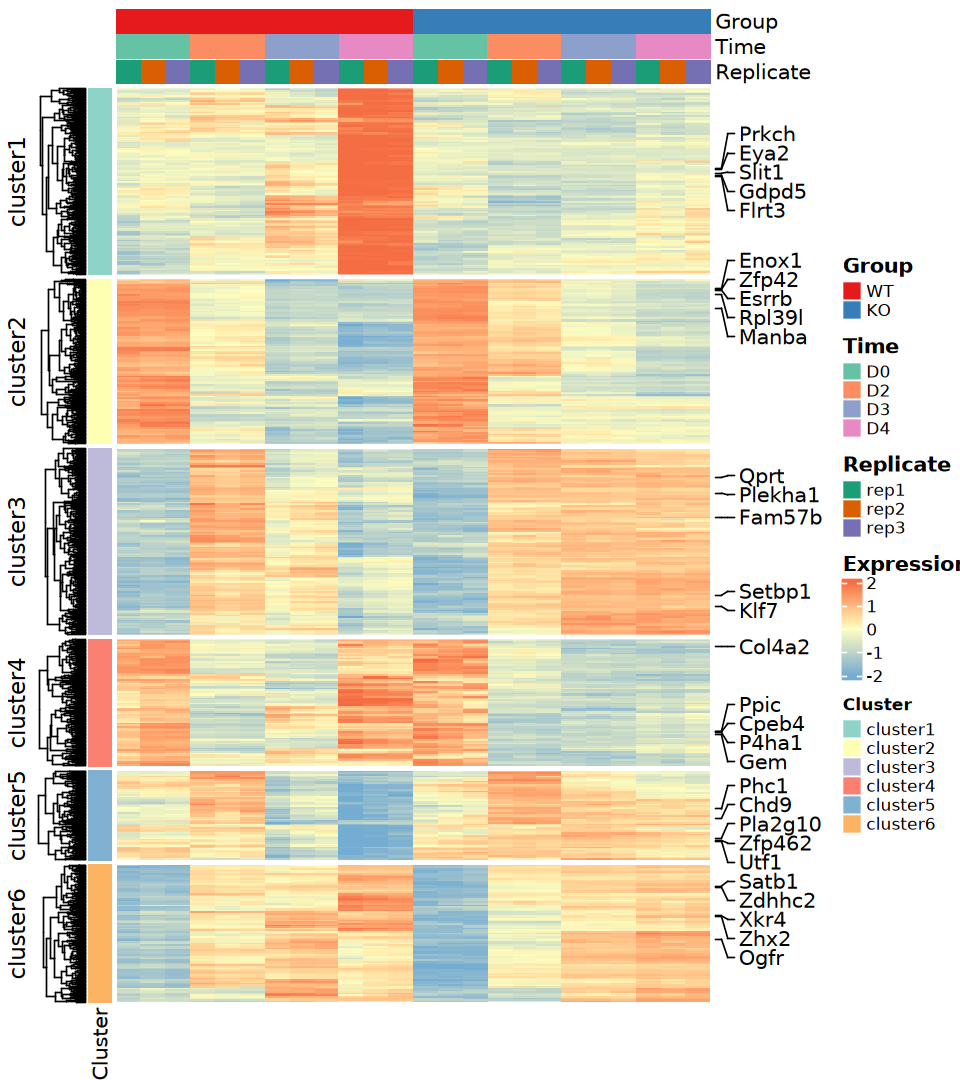

In [197]:
options(repr.plot.width = 8, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_cluster), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

In [198]:
go_annotations <- ego_cluster_compare |> as.data.frame() |> 
    dplyr::select(Cluster, ONTOLOGY, ID, Description, p.adjust, Count) |>
    mutate(
        ONTOLOGY = factor(ONTOLOGY, levels = c("BP", "MF", "CC")),
        GO_term = paste0(Description, " (", ONTOLOGY, ")")) |>
    group_by(Cluster) |> 
    arrange(ONTOLOGY, p.adjust, .by_group = TRUE) |>
    slice_head(n = 5) |>
    summarise(GO_term = paste(GO_term, collapse = "\n")) |>
    mutate(Cluster = factor(paste0("cluster", Cluster)))

In [199]:
go_term_data_list <- split(go_annotations$GO_term, go_annotations$Cluster)

In [200]:
right_annotation <- rowAnnotation(
    textbox = anno_textbox(
        ar$Cluster, go_term_data_list,
        background_gp = gpar(fill = "#ffffff"),
        gp = gpar(fontsize = 12), max_width = unit(10, "cm"), 
        add_new_line = TRUE, round_corners = TRUE), 
    width = unit(12, "cm"))
# word_wrap = TRUE, 

In [201]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        show_row_names = FALSE, show_column_names = FALSE, 
        width = unit(8, "cm"), use_raster = TRUE) +
    Heatmap(
        ar$Cluster, name = "Cluster", 
        col = cluster_colors,
        show_column_names = FALSE,
        right_annotation = right_annotation,
        width = unit(0.3, "cm"))

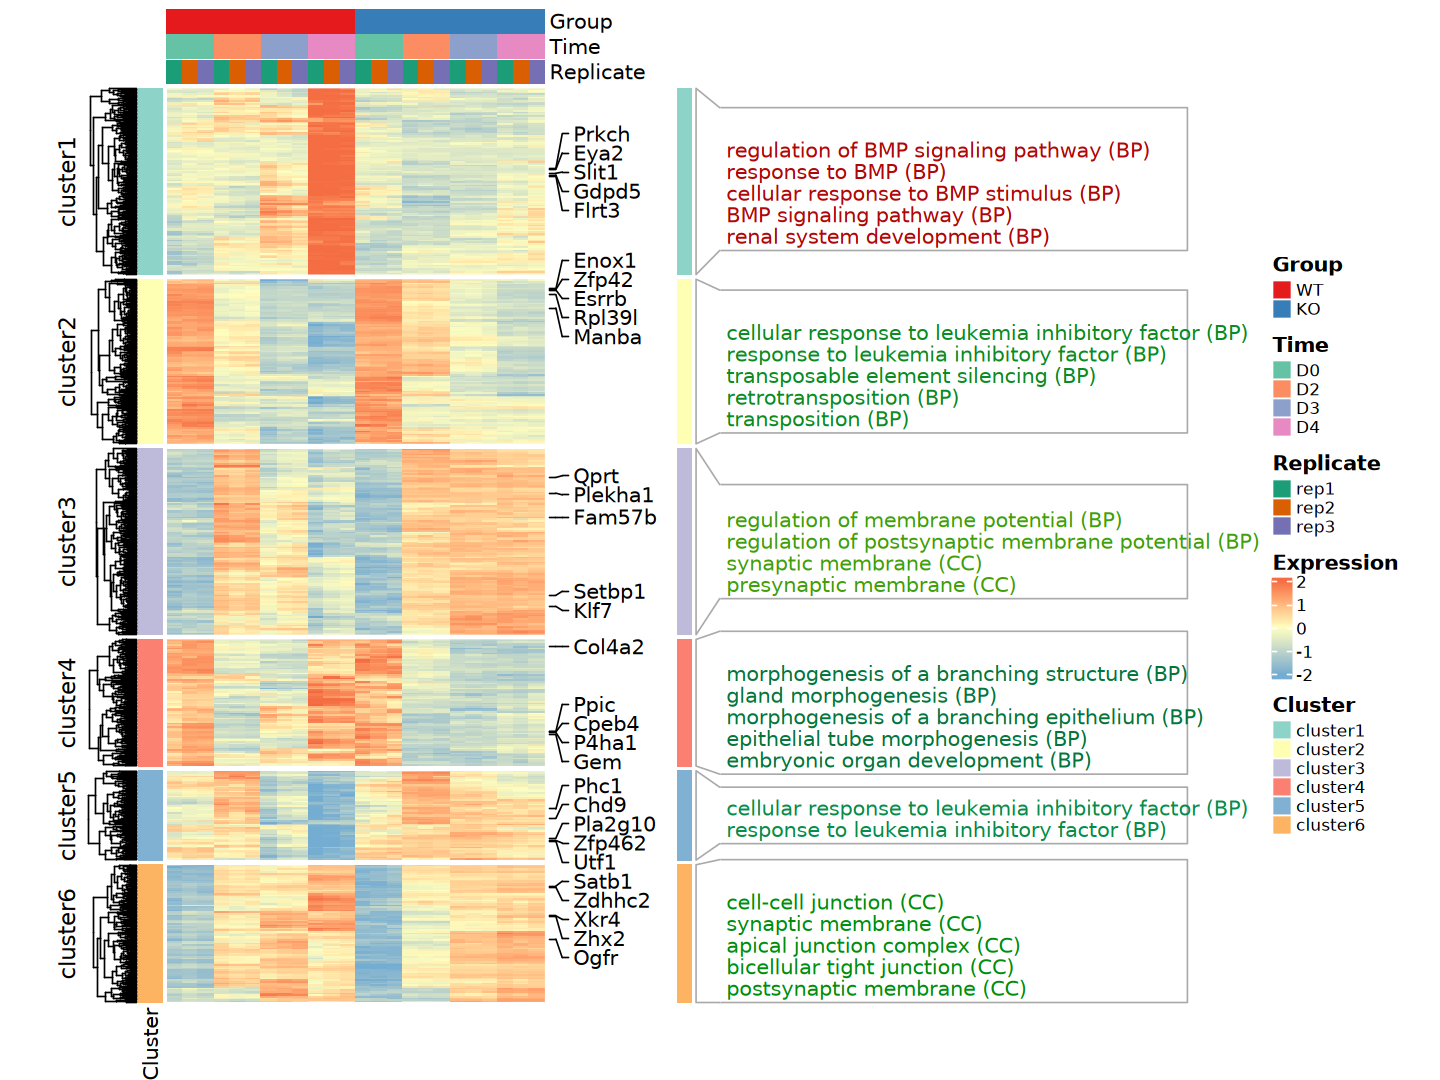

In [202]:
options(repr.plot.width = 12, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE,
    # annotation_legend_list = list(lg_cluster), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

In [203]:
s_heatmap_dat <- heatmap_dat |> t() |> scale() |> t()

In [204]:
panel_fun_boxplot <- function(s_heatmap_dat, group_colors = NULL) {
    function(index, nm) {
        tmp <- s_heatmap_dat[index, , drop = FALSE]
        pos <- seq(0, 1, length.out = ncol(tmp))
        rng <- range(tmp, na.rm = TRUE)
        norm <- (tmp - rng[1]) / (rng[2] - rng[1])
        fills <- if (is.null(group_colors)) "grey70" else group_colors |>
            rep(each = 3)
        bw <- min(0.1, 0.9 / max(1, ncol(tmp)))

        grid::pushViewport(grid::viewport(xscale = c(-0.1, 1.1), yscale = c(0, 1.2)))
        grid::grid.rect()                         
        for (i in seq_len(ncol(norm))) {
            grid.boxplot(
                norm[, i], pos = pos[i],
                direction = "vertical",
                box_width = bw, outline = FALSE,
                gp = grid::gpar(col = "grey50", fill = fills[i]))
        }
        grid::grid.lines(
            x = pos, y = apply(norm, 2, median, na.rm = TRUE),
            gp = grid::gpar(col = "red", lwd = 0.5))
        grid::grid.text(
            paste0("Genes: ", nrow(tmp)), 0.5, 0.9, 
            gp = grid::gpar(fontsize = 6))
        grid::popViewport()
    }
}

In [205]:
groups <- eSet$Group
times  <- eSet$Time
group_time_tags <- paste(groups, times, sep = "_")
group_time_levels <- unique(group_time_tags) 

wt_colors <- scales::brewer_pal(palette = "Blues")(5)[2:5]
ko_colors <- scales::brewer_pal(palette = "Reds")(5)[2:5]

group_time_colors <- setNames(c(wt_colors, ko_colors), group_time_levels)

In [206]:
panel_fun <- panel_fun_boxplot(s_heatmap_dat, group_time_colors)
left_anno2 <- rowAnnotation(
    boxplot = anno_link(
        align_to = factor(ar$Cluster), which = "row",
        panel_fun = panel_fun, side = "left",
        size = grid::unit(3, "cm"),
        width = grid::unit(6, "cm"),
        gap = grid::unit(0.25, "cm"),
        link_gp = grid::gpar(fill = "grey90", col = NA)))

In [207]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        top_annotation = top_anno,
        left_annotation = left_anno2, 
        right_annotation = right_anno,
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        show_row_names = FALSE, show_column_names = FALSE, 
        show_row_dend = FALSE,
        width = unit(8, "cm"), use_raster = TRUE) +
    Heatmap(
        ar$Cluster, name = "Cluster", 
        col = cluster_colors,
        show_column_names = FALSE,
        right_annotation = right_annotation,
        width = unit(0.3, "cm"))

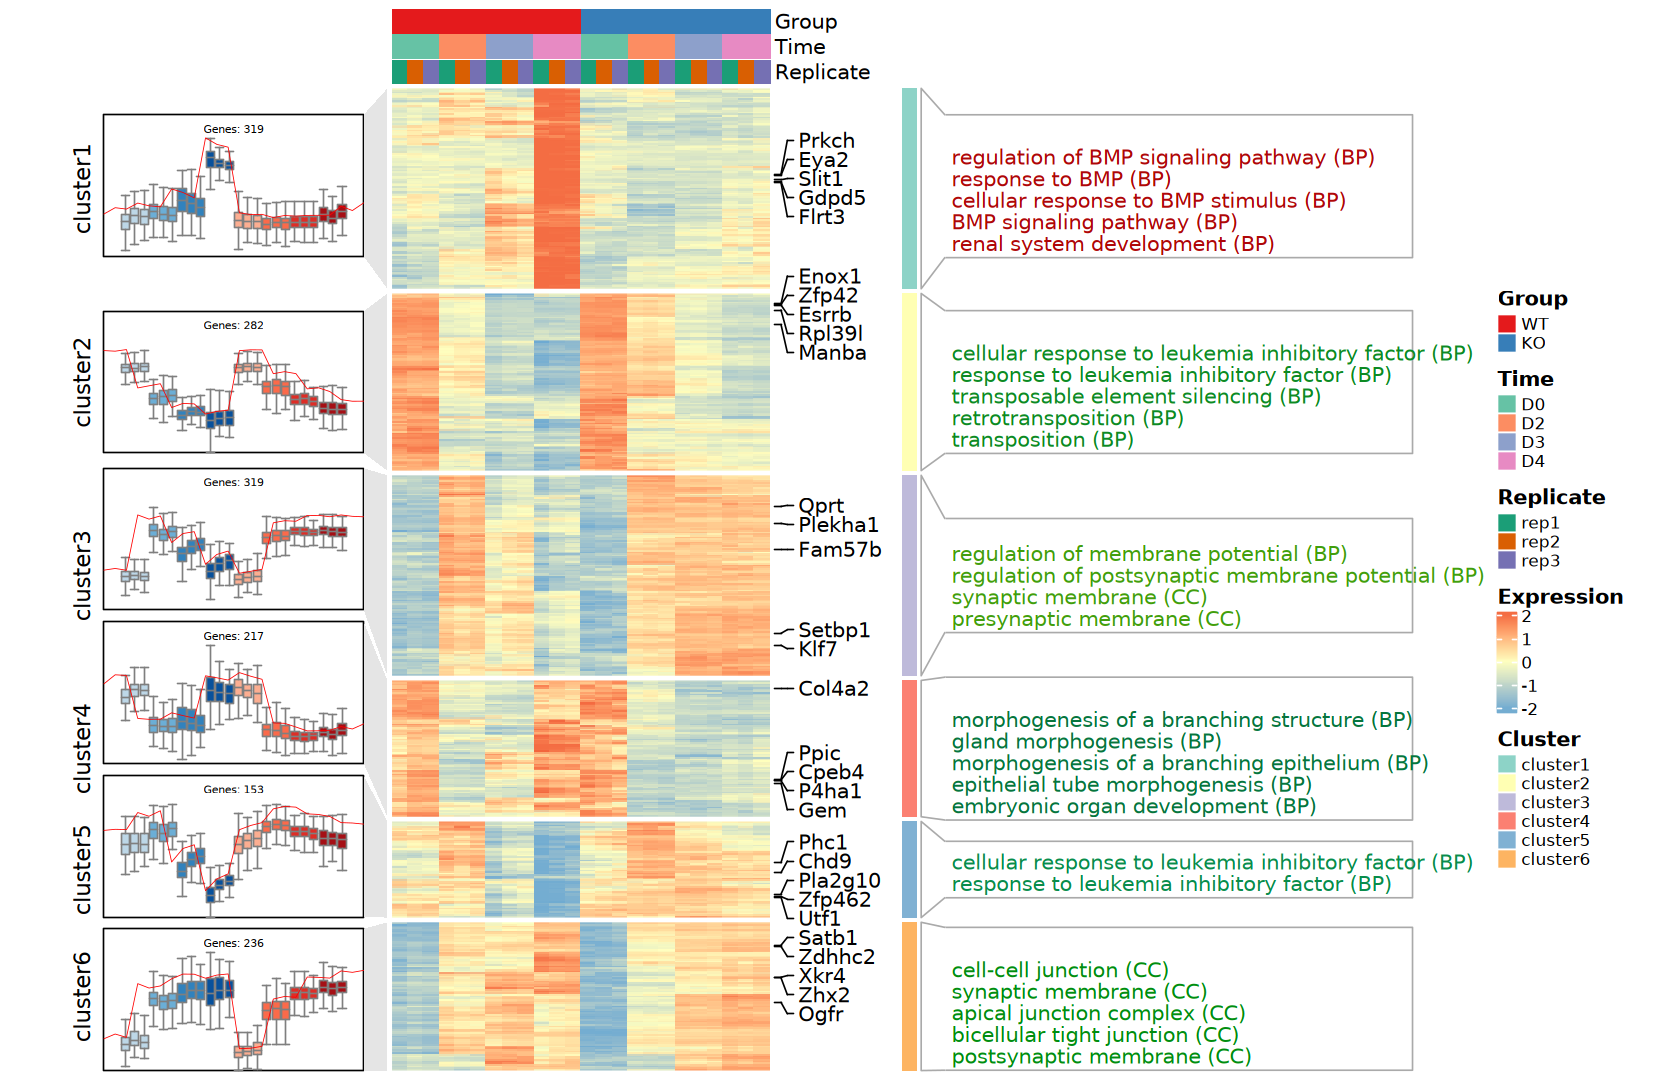

In [208]:
options(repr.plot.width = 14, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE,
    # annotation_legend_list = list(lg_cluster), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

In [209]:
panel_fun_pathplot <- function(
    s_heatmap_dat, cluster_df, palette = c("blue","white","red")) {
    
    function(index, nm) {
        tmp <- s_heatmap_dat[index, , drop = FALSE]
        # pos <- scales::rescale(1:ncol(tmp), to = c(0, 1))
        pos <- seq(0, 1, length.out = ncol(tmp))
        rng <- range(tmp, na.rm = TRUE)
        norm <- (tmp - rng[1]) / (rng[2] - rng[1])
        
        mem <- cluster_df$membership[match(rownames(tmp), cluster_df$gene_id)]
        mem_idx <- round(mem * 100)
        line_colors <- grDevices::colorRampPalette(palette)(100)
        line_cols <- line_colors[mem_idx]

        pushViewport(grid::viewport(xscale = c(-0.1, 1.1), yscale = c(0, 1.2)))
        grid.rect()
        for (i in seq_len(nrow(norm))) {
            grid.lines(
                x = pos, y = norm[i, ], 
                gp = gpar(col = line_cols[i], lwd = 0.5))
        }
        grid.text(paste0("Genes: ", nrow(tmp)), 0.5, 0.9, gp = grid::gpar(fontsize = 6))
        popViewport()
    }
}

In [210]:
palette = c(
    "#5E4FA2", "#3288BD", "#66C2A5", "#ABDDA4", 
    "#E6F598", "#FFFFBF", "#FEE08B", "#FDAE61", 
    "#F46D43", "#D53E4F", "#9E0142")

In [211]:
panel_fun <- panel_fun_pathplot(s_heatmap_dat, cluster_df, palette)
left_anno3 <- rowAnnotation(
    boxplot = anno_link(
        align_to = factor(ar$Cluster), which = "row",
        panel_fun = panel_fun, side = "left",
        size = grid::unit(3, "cm"),
        width = grid::unit(6, "cm"),
        gap = grid::unit(0.25, "cm"),
        link_gp = grid::gpar(fill = "grey90", col = NA)))

In [212]:
line_colors <- circlize::colorRamp2(
    breaks = seq(0, 1, length.out = length(palette)), 
    colors = palette)

lg_line <- Legend(
    title = "Membership", col_fun = line_colors, 
    at = c(0, 0.5, 1), labels = c("0", "0.5", "1"))

In [213]:
combined_leg <- list(lg_heatmap, lg_group, lg_replicate, lg_line) |>
    packLegend(direction = "vertical")

In [214]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        top_annotation = top_anno,
        left_annotation = left_anno3, 
        right_annotation = right_anno,
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        show_row_names = FALSE, show_column_names = FALSE, 
        show_row_dend = FALSE,
        width = unit(8, "cm"), use_raster = TRUE) +
    Heatmap(
        ar$Cluster, name = "Cluster", 
        col = cluster_colors,
        show_column_names = FALSE,
        right_annotation = right_annotation,
        width = unit(0.3, "cm"))

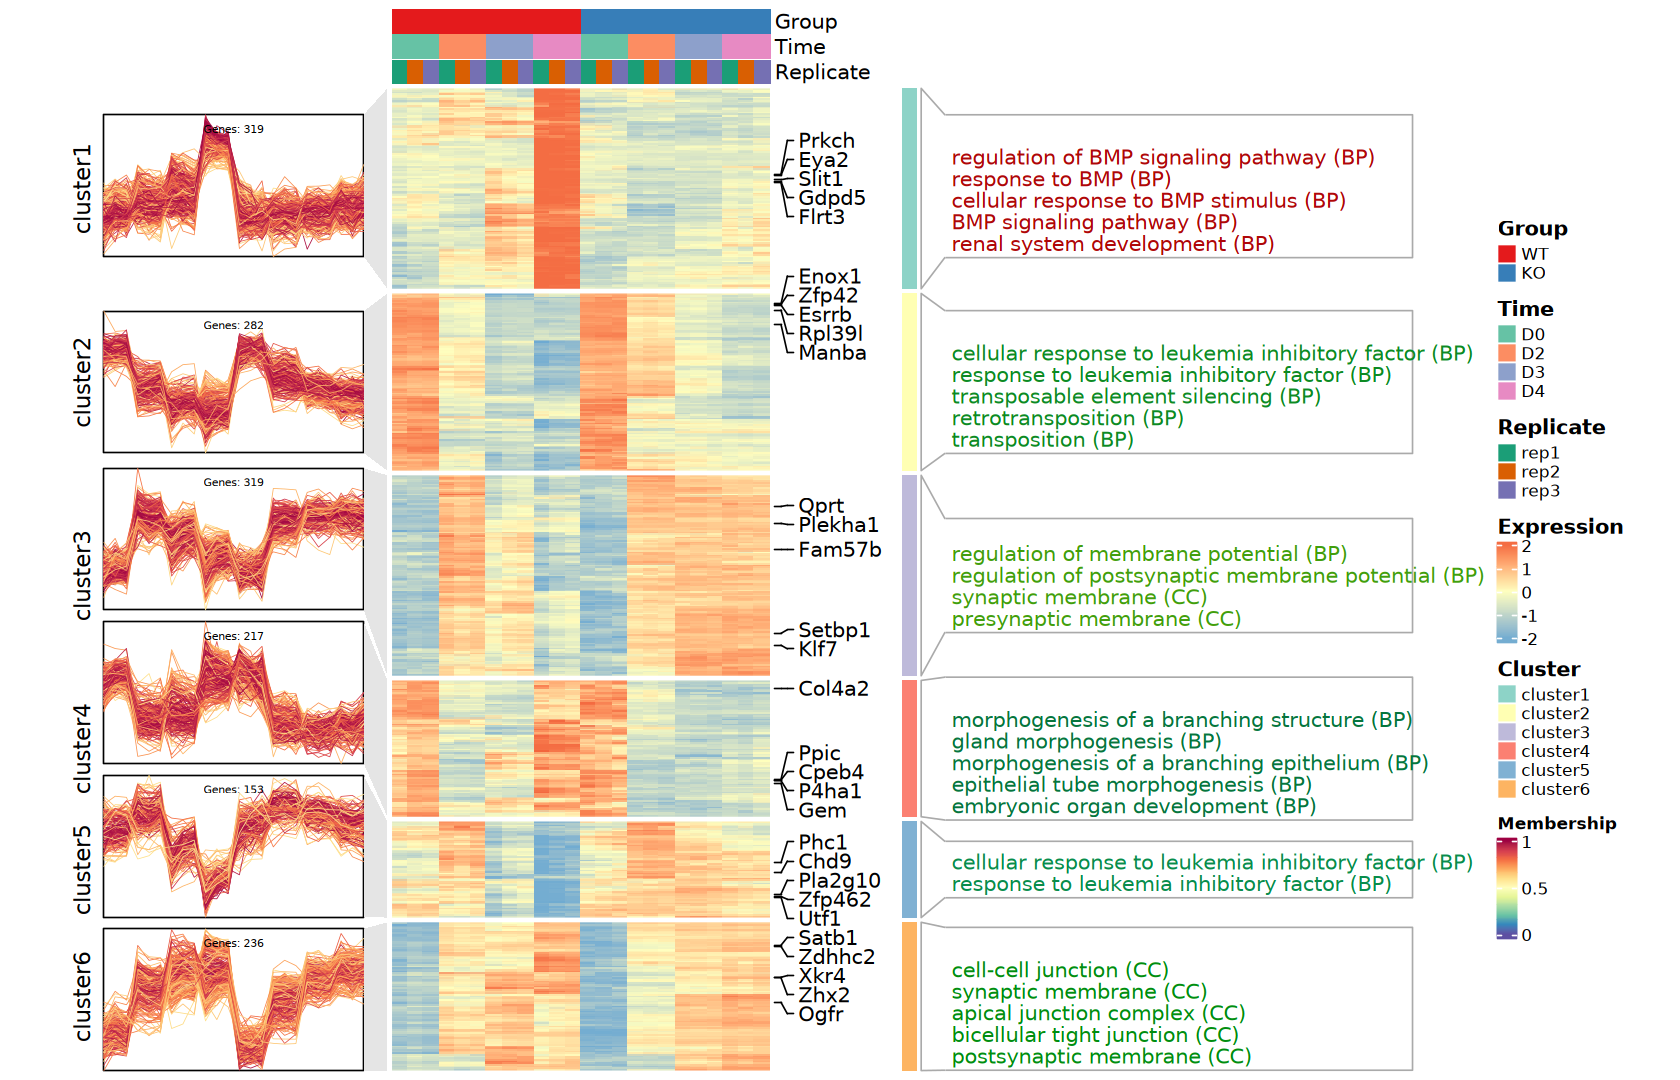

In [215]:
options(repr.plot.width = 14, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_line),
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

#### 3). [ClusterGVis](https://github.com/junjunlab/ClusterGVis)

> - To enhance clustering and visualization of time-series gene expression data from RNA-Seq experiments.

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)